# Registros de Pacientes como Base para Decisão Clínica
### Evolução de IMC, função pulmonar e internações em crianças acompanhadas (6 anos → 1 ano depois)

---
**Objetivo:** demonstrar como uma base de **registro longitudinal de pacientes** apoia decisões: avaliar se um tratamento está funcionando, prever desfechos e identificar o que a base ainda precisa capturar.

| Pergunta | Técnica | Seção |
|---|---|---|
| Como estão os dados e quem são os pacientes? | Estatística descritiva e visualização | 1–3 |
| O que prevê a função pulmonar? | Regressão linear (MAE, RMSE, R²) | 4 |
| É possível prever internações? | Regressão logística (matriz de confusão, precisão, recall, F1) | 5 |
| O tratamento funcionou dos 6 aos 7 anos? | Comparação pareada + critérios de sucesso | 6 |
| Quem merece atenção agora? | Lista de triagem a partir do registro | 7 |

> **Critérios de sucesso do tratamento:** (1) melhora ou estabilização do IMC, (2) diminuição de internações, (3) melhora da função pulmonar.

**Como ler este notebook:** cada gráfico traz título, eixos identificados e uma interpretação gerada a partir dos próprios números. Se a base mudar, o texto muda junto.

---
## 1. Preparação dos Dados

In [18]:
# -- Importação de bibliotecas ----------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, accuracy_score)
from IPython.display import display

# Paleta para superfície escura (azul/laranja = identidade; verde/vermelho = status)
C = dict(azul='#3987e5', laranja='#d95926', agua='#199e70', violeta='#9085e9',
         bom='#0ca30c', critico='#d03b3b', neutro='#898781',
         tinta='#f0efec', tinta2='#c3c2b7', grade='#2c2c2a', eixo='#383835',
         superficie='#1a1a19', fundo='#0d0d0d')

plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': C['fundo'], 'savefig.facecolor': C['fundo'],
    'axes.facecolor': C['superficie'], 'axes.edgecolor': C['eixo'],
    'axes.labelcolor': C['tinta2'], 'axes.titlecolor': C['tinta'],
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': C['grade'], 'grid.linestyle': '-', 'grid.linewidth': 0.8,
    'xtick.color': C['neutro'], 'ytick.color': C['neutro'], 'text.color': C['tinta'],
    'legend.facecolor': C['superficie'], 'legend.edgecolor': C['eixo'],
    'font.size': 10,
})

CMAP_DIV = LinearSegmentedColormap.from_list('div', ['#e66767', '#383835', '#3987e5'])   # azul <-> vermelho
CMAP_SEQ = LinearSegmentedColormap.from_list('seq', ['#0d366b', '#3987e5', '#9ec5f4'])   # uma só matiz

os.makedirs('figures', exist_ok=True)

def mostrar(fig, nome):
    # salva o gráfico em figures/ (usado no README) e exibe no notebook
    fig.savefig(f'figures/{nome}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    plt.show()

def br(x, nd=2):
    # número no formato brasileiro (vírgula decimal) para os textos de interpretação
    return f'{x:.{nd}f}'.replace('.', ',')

print('Bibliotecas importadas com sucesso.')

Bibliotecas importadas com sucesso.


In [62]:
# -- Parâmetros da análise ----------------------------------------------------
CSV_PATH = 'dados_fin.csv'
DIA_REF_SEGUIMENTO = '12-31'   # a base só traz o ANO do seguimento, não há datas das consultas de cada ano (quantidade de consultas suprimida pois não é relevante)
IDADE_BASE, IDADE_POS = 6, 7   # momentos comparados: 6 anos vs 1 ano depois
TOL_IMC = 0.5                  # kg/m²: variações dentro de ±0,5 contam como "estabilização"
LIN_Z = -1.645                 # limite inferior da normalidade (percentil 5) em escore Z
RANDOM_STATE = 42

# -- Importação e tratamento da base ------------------------------------------
df = pd.read_csv(CSV_PATH, parse_dates=['data_nasc','data_diagn'],dayfirst=True)
# -- Leitura da base ----------------------------------------------------------
print(f'Base carregada: {df.shape[0]} registros, {df.shape[1]} colunas, {df["idpaciente"].nunique()} pacientes únicos')
print(f'Anos de seguimento: {sorted(int(a) for a in df["ano_seguimento"].unique())}')
reg_por_pac = df.groupby('idpaciente').size().value_counts().sort_index()
print('Registros por paciente: ' + ' | '.join(f'{k} registro(s): {v} pacientes' for k, v in reg_por_pac.items()))

# -- Identificação dos tipos de dados -----------------------------------------
print(df.dtypes)

print('\n-- DICIONÁRIO DE VARIÁVEIS ------------------------------------')
dicionario = {
    'idpaciente':       'Identificador único do paciente',
    'data_nasc':        'Data de nascimento (dd/mm/aaaa)',
    'data_diagn':       'Data do diagnóstico (dd/mm/aaaa)',
    'ano_seguimento':   'Ano da consulta de seguimento',
    'imc':              'Índice de massa corporal (kg/m²)',
    'internacao':       'Houve internação (True/False) no registro do seguimento',
    'VEF1 Z':           'VEF1 em escore Z (0 = média da população de referência)',
    'VEF1 Predito':     'VEF1 em % do predito (derivado do escore Z)',
    'CVF Z':            'CVF em escore Z',
    'CVF Predito':      'CVF em % do predito (derivado do escore Z)',
    'VEF1/CVF':         'Razão VEF1/CVF (índice de Tiffeneau)',
    'VEF1/CVF Predito': 'Razão VEF1/CVF predita (%)',
    'VEF1/CVF Z':       'Razão VEF1/CVF em escore Z',
    'VEF1/CVF Tile':    'Percentil (0–100) correspondente ao escore Z da razão',
}
for col, desc in dicionario.items():
    print(f'  {col:<18} → {desc}')

# -- Valores ausentes e duplicados --------------------------------------------
n_aus = int(df.isnull().sum().sum())
n_dup = int(df.duplicated().sum())
n_dup_ano = int(df.duplicated(['idpaciente', 'ano_seguimento']).sum())
print(f'\nValores ausentes na base: {n_aus}')
print(f'Linhas duplicadas: {n_dup} | Pacientes com 2+ registros no mesmo ano: {n_dup_ano}')

Base carregada: 83 registros, 14 colunas, 41 pacientes únicos
Anos de seguimento: [2022, 2023, 2024, 2025]
Registros por paciente: 1 registro(s): 2 pacientes | 2 registro(s): 36 pacientes | 3 registro(s): 3 pacientes
idpaciente                     str
data_nasc           datetime64[us]
data_diagn          datetime64[us]
ano_seguimento               int64
imc                            str
internacao                    bool
VEF1 Z                         str
VEF1 Predito                   str
CVF Z                          str
CVF Predito                    str
VEF1/CVF                       str
VEF1/CVF Predito             int64
VEF1/CVF Z                     str
VEF1/CVF Tile                  str
dtype: object

-- DICIONÁRIO DE VARIÁVEIS ------------------------------------
  idpaciente         → Identificador único do paciente
  data_nasc          → Data de nascimento (dd/mm/aaaa)
  data_diagn         → Data do diagnóstico (dd/mm/aaaa)
  ano_seguimento     → Ano da consulta de seguim

In [ ]:
# -- Datas, idade e variáveis derivadas ---------------------------------------
df['data_nasc']  = pd.to_datetime(df['data_nasc'],  format='%d/%m/%Y')
df['data_diagn'] = pd.to_datetime(df['data_diagn'], format='%d/%m/%Y')

def adicionar_idade(base, mmdd=DIA_REF_SEGUIMENTO):
    # data_seguimento = mm-dd escolhido do ano do seguimento; idade = (data_seguimento - data_nasc) em anos.
    d = base.copy()
    d['data_seguimento'] = pd.to_datetime(d['ano_seguimento'].astype(str) + '-' + mmdd)
    d['idade'] = (d['data_seguimento'] - d['data_nasc']).dt.days / 365.25
    d['idade_inteira'] = np.floor(d['idade']).astype(int)
    return d

df = adicionar_idade(df)
df['idade_diagnostico'] = (df['data_diagn'] - df['data_nasc']).dt.days / 365.25
df['internacao_int'] = df['internacao'].astype(int)

display(df[['idpaciente', 'data_nasc', 'ano_seguimento', 'data_seguimento', 'idade', 'idade_inteira']].head(6))

print(f'Idade no seguimento: {df["idade"].min():.1f} a {df["idade"].max():.1f} anos (média {df["idade"].mean():.1f})')
print(f'Idades inteiras presentes: {sorted(int(a) for a in df["idade_inteira"].unique())}')
print(f'Diagnóstico anterior ao nascimento: {int((df["data_diagn"] < df["data_nasc"]).sum())} registros')
print(f'Seguimento anterior ao diagnóstico: {int((df["data_seguimento"] < df["data_diagn"]).sum())} registros')
tardios = df.loc[df['idade_diagnostico'] > 2, 'idpaciente'].unique()
print(f'Diagnóstico tardio (> 2 anos de idade): {list(tardios)}  | mediana geral: {df["idade_diagnostico"].median()*12:.1f} meses')

# -- Qualidade: valores espirométricos implausíveis ---------------------------
LIMITE_Z = 4
suspeitos = df[(df[['VEF1 Z', 'CVF Z', 'VEF1/CVF Z']].abs() > LIMITE_Z).any(axis=1)]
print(f'\nRegistros com |Z| > {LIMITE_Z} (provável erro de medição): {len(suspeitos)}')
if len(suspeitos):
    display(suspeitos[['idpaciente', 'ano_seguimento', 'VEF1 Z', 'CVF Z', 'CVF Predito', 'VEF1/CVF']])
    so_um = suspeitos['idpaciente'].map(df.groupby('idpaciente').size()).eq(1).all()
    print('Mantido na base e sinalizado: o registro segue nos modelos (via VEF1 Z e VEF1/CVF Z, que parecem coerentes), mas CVF Z não é usado como preditor nem desfecho. '
          + ('Como esse paciente tem um único registro, ele não forma par de anos consecutivos e não entra nas comparações 6 → 7 anos.' if so_um
             else 'Atenção: há pacientes sinalizados com mais de um registro.'))

,idpaciente,data_nasc,ano_seguimento,data_seguimento,idade,idade_inteira
0,trrul-3,2016-12-18,2024,2024-12-31,8.035592,8
1,trrul-3,2016-12-18,2025,2025-12-31,9.034908,9
2,5ygm1-8,2018-04-08,2024,2024-12-31,6.732375,6
3,5ygm1-8,2018-04-08,2025,2025-12-31,7.731691,7
4,bwrry-0,2016-11-29,2024,2024-12-31,8.087611,8
5,bwrry-0,2016-11-29,2025,2025-12-31,9.086927,9


Idade no seguimento: 6.0 a 10.8 anos (média 8.6)
Idades inteiras presentes: [6, 7, 8, 9, 10]
Diagnóstico anterior ao nascimento: 0 registros
Seguimento anterior ao diagnóstico: 0 registros
Diagnóstico tardio (> 2 anos de idade): ['bwuub-3']  | mediana geral: 1.7 meses

Registros com |Z| > 4 (provável erro de medição): 1


,idpaciente,ano_seguimento,VEF1 Z,CVF Z,CVF Predito,VEF1/CVF
31,hv5am-1,2025,1.1,6.13,184.8,0.56


Mantido na base e sinalizado: o registro segue nos modelos (via VEF1 Z e VEF1/CVF Z, que parecem coerentes), mas CVF Z não é usado como preditor nem desfecho. Como esse paciente tem um único registro, ele não forma par de anos consecutivos e não entra nas comparações 6 → 7 anos.


---
## 2. Estatística Descritiva

In [4]:
# -- Medidas de Tendência Central e Dispersão ---------------------------------
print('=' * 70)
print('  TENDÊNCIA CENTRAL E DISPERSÃO')
print('=' * 70)
VARS_DESC = ['idade', 'imc', 'VEF1 Z', 'VEF1 Predito', 'CVF Z', 'CVF Predito', 'VEF1/CVF', 'VEF1/CVF Z']
rows = []
for v in VARS_DESC:
    s = df[v]
    cv = np.nan if v.endswith(' Z') else s.std() / s.mean() * 100   # CV não faz sentido com média ≈ 0
    rows.append({'Variável': v, 'Média': s.mean(), 'Mediana': s.median(), 'Moda': s.mode().iloc[0],
                 'Desvio padrão': s.std(), 'CV (%)': cv, 'Mín': s.min(), 'Máx': s.max(),
                 'Amplitude': s.max() - s.min()})
desc_df = pd.DataFrame(rows).set_index('Variável')
display(desc_df.style.format('{:.2f}', na_rep='—'))

imc = df['imc']
print(f"IMC: média {br(imc.mean())} kg/m² e mediana {br(imc.median())} (CV {br(desc_df.loc['imc', 'CV (%)'], 1)}%).")
print(f"VEF1 Z: média {br(df['VEF1 Z'].mean())} e DP {br(df['VEF1 Z'].std())}; uma população de referência teria média 0 e DP 1, "
      f"então a coorte é, em média, comparável ao esperado.")
print('CV omitido para escores Z: com média próxima de zero o coeficiente de variação perde o sentido.')

# -- Medidas Posicionais e Outliers (IQR e Z-score) ---------------------------
print('\n' + '=' * 70)
print('  QUARTIS, PERCENTIS E OUTLIERS')
print('=' * 70)
rows = []
for v in VARS_DESC:
    s = df[v]
    q1, q2, q3 = s.quantile([.25, .5, .75])
    iqr = q3 - q1
    lim_i, lim_s = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_iqr = int(((s < lim_i) | (s > lim_s)).sum())
    n_z = int((np.abs(stats.zscore(s)) > 3).sum())
    rows.append({'Variável': v, 'P5': s.quantile(.05), 'Q1': q1, 'Mediana': q2, 'Q3': q3, 'P95': s.quantile(.95),
                 'IQR': iqr, 'Outliers IQR': n_iqr, '% IQR': n_iqr / len(s) * 100, 'Outliers |z|>3': n_z})
pos_df = pd.DataFrame(rows).set_index('Variável')
display(pos_df.style.format('{:.2f}', subset=['P5', 'Q1', 'Mediana', 'Q3', 'P95', 'IQR', '% IQR']))

com_out = pos_df[pos_df['Outliers IQR'] > 0].sort_values('Outliers IQR', ascending=False)
if len(com_out):
    print('Variáveis com outliers pelo critério IQR: ' +
          '; '.join(f"{v} ({int(r['Outliers IQR'])})" for v, r in com_out.iterrows()) + '.')
else:
    print('Nenhum outlier pelo critério IQR.')
print(f"Maior CVF Z observado: {df['CVF Z'].max():.2f} (CVF = {df.loc[df['CVF Z'].idxmax(), 'CVF Predito']:.0f}% do predito), "
      "incompatível com uma medição confiável; ver sinalização na seção 1.")

  TENDÊNCIA CENTRAL E DISPERSÃO


,Média,Mediana,Moda,Desvio padrão,CV (%),Mín,Máx,Amplitude
Variável,,,,,,,,
idade,8.60,8.62,9.40,1.28,14.92,6.04,10.84,4.79
imc,16.46,16.06,15.24,2.28,13.85,13.14,25.83,12.69
VEF1 Z,-0.02,0.20,-0.52,1.20,—,-3.35,2.02,5.37
VEF1 Predito,99.61,102.35,59.24,14.51,14.56,59.24,125.73,66.49
CVF Z,0.10,0.15,0.91,1.30,—,-3.44,6.13,9.57
CVF Predito,101.62,101.80,103.73,16.45,16.19,59.76,184.80,125.04
VEF1/CVF,0.88,0.90,0.91,0.08,8.66,0.56,1.00,0.44
VEF1/CVF Z,-0.18,-0.04,0.13,1.10,—,-3.25,1.95,5.20


IMC: média 16,46 kg/m² e mediana 16,06 (CV 13,8%).
VEF1 Z: média -0,02 e DP 1,20; uma população de referência teria média 0 e DP 1, então a coorte é, em média, comparável ao esperado.
CV omitido para escores Z: com média próxima de zero o coeficiente de variação perde o sentido.

  QUARTIS, PERCENTIS E OUTLIERS


,P5,Q1,Mediana,Q3,P95,IQR,Outliers IQR,% IQR,Outliers |z|>3
Variável,,,,,,,,,
idade,6.53,7.52,8.62,9.61,10.54,2.08,0,0.00,0
imc,13.86,14.73,16.06,17.54,20.15,2.81,3,3.61,1
VEF1 Z,-2.30,-0.62,0.20,0.78,1.60,1.40,3,3.61,0
VEF1 Predito,73.05,92.64,102.35,109.28,118.80,16.64,3,3.61,0
CVF Z,-1.83,-0.54,0.15,0.87,1.69,1.42,3,3.61,1
CVF Predito,77.30,93.13,101.80,110.88,121.85,17.75,3,3.61,1
VEF1/CVF,0.74,0.86,0.90,0.93,0.98,0.07,8,9.64,1
VEF1/CVF Z,-2.17,-0.75,-0.04,0.53,1.45,1.27,2,2.41,0


Variáveis com outliers pelo critério IQR: VEF1/CVF (8); VEF1 Z (3); imc (3); VEF1 Predito (3); CVF Z (3); CVF Predito (3); VEF1/CVF Z (2).
Maior CVF Z observado: 6.13 (CVF = 185% do predito), incompatível com uma medição confiável; ver sinalização na seção 1.


In [5]:
# -- Análise de Distribuição: Assimetria e Curtose ----------------------------
print('=' * 70)
print('  FORMA DAS DISTRIBUIÇÕES')
print('=' * 70)
rows = []
for v in VARS_DESC:
    s = df[v]
    sk, kt = s.skew(), s.kurtosis()
    assi = 'Positiva ▶' if sk > 0.5 else ('Negativa ◀' if sk < -0.5 else 'Aproximadamente simétrica ◆')
    curt = 'Leptocúrtica ▲' if kt > 1 else ('Platicúrtica ▼' if kt < -1 else 'Mesocúrtica —')
    p_norm = stats.shapiro(s).pvalue
    rows.append({'Variável': v, 'Assimetria': round(sk, 2), 'Tipo': assi, 'Curtose': round(kt, 2),
                 'Forma': curt, 'Shapiro-Wilk p': round(p_norm, 3)})
dist_df = pd.DataFrame(rows).set_index('Variável')
display(dist_df)

nao_normais = dist_df[dist_df['Shapiro-Wilk p'] < 0.05].index.tolist()
print('Rejeitam normalidade (Shapiro-Wilk, p < 0,05): ' + (', '.join(nao_normais) if nao_normais else 'nenhuma') + '.')
print('Com amostras pequenas, testes não paramétricos (Wilcoxon, Mann-Whitney) são a escolha segura nas comparações adiante.')

  FORMA DAS DISTRIBUIÇÕES


,Assimetria,Tipo,Curtose,Forma,Shapiro-Wilk p
Variável,,,,,
idade,-0.11,Aproximadamente simétrica ◆,-0.98,Mesocúrtica —,0.057
imc,1.37,Positiva ▶,3.10,Leptocúrtica ▲,0.000
VEF1 Z,-0.71,Negativa ◀,0.13,Mesocúrtica —,0.009
VEF1 Predito,-0.71,Negativa ◀,0.15,Mesocúrtica —,0.010
CVF Z,0.67,Positiva ▶,5.11,Leptocúrtica ▲,0.000
CVF Predito,1.14,Positiva ▶,7.21,Leptocúrtica ▲,0.000
VEF1/CVF,-1.50,Negativa ◀,3.27,Leptocúrtica ▲,0.000
VEF1/CVF Z,-0.54,Negativa ◀,0.02,Mesocúrtica —,0.034


Rejeitam normalidade (Shapiro-Wilk, p < 0,05): imc, VEF1 Z, VEF1 Predito, CVF Z, CVF Predito, VEF1/CVF, VEF1/CVF Z.
Com amostras pequenas, testes não paramétricos (Wilcoxon, Mann-Whitney) são a escolha segura nas comparações adiante.


In [6]:
# -- Perfil por internação ------------------------------------------------------
print('=' * 70)
print('  PERFIL DOS REGISTROS COM E SEM INTERNAÇÃO')
print('=' * 70)
VARS_PERFIL = ['idade', 'imc', 'VEF1 Z', 'CVF Z', 'VEF1/CVF Z']
rows = []
for v in VARS_PERFIL:
    sem = df.loc[~df['internacao'], v]
    com = df.loc[df['internacao'], v]
    rows.append({'Variável': v, 'Média sem internação': sem.mean(), 'Média com internação': com.mean(),
                 'Diferença': com.mean() - sem.mean(), 'Mann-Whitney p': stats.mannwhitneyu(com, sem).pvalue})
perfil_df = pd.DataFrame(rows).set_index('Variável')
display(perfil_df.style.format('{:.3f}'))

taxa = df['internacao'].mean() * 100
print(f"Internação em {int(df['internacao'].sum())} de {len(df)} registros ({br(taxa, 1)}%).")
sig = perfil_df[perfil_df['Mann-Whitney p'] < 0.05]
if len(sig):
    print('Diferenças estatisticamente significativas: ' + ', '.join(sig.index) + '.')
else:
    print('Nenhuma variável difere significativamente entre registros com e sem internação (todos os p ≥ 0,05); '
          'isso antecipa a dificuldade de prever internações na seção 5.')

  PERFIL DOS REGISTROS COM E SEM INTERNAÇÃO


,Média sem internação,Média com internação,Diferença,Mann-Whitney p
Variável,,,,
idade,8.663,8.357,-0.306,0.377
imc,16.645,15.662,-0.983,0.162
VEF1 Z,0.032,-0.259,-0.291,0.359
CVF Z,0.204,-0.310,-0.514,0.192
VEF1/CVF Z,-0.252,0.115,0.367,0.237


Internação em 16 de 83 registros (19,3%).
Nenhuma variável difere significativamente entre registros com e sem internação (todos os p ≥ 0,05); isso antecipa a dificuldade de prever internações na seção 5.


---
## 3. Visualizações Exploratórias

> Cada gráfico contém título, identificação dos eixos e interpretação analítica.

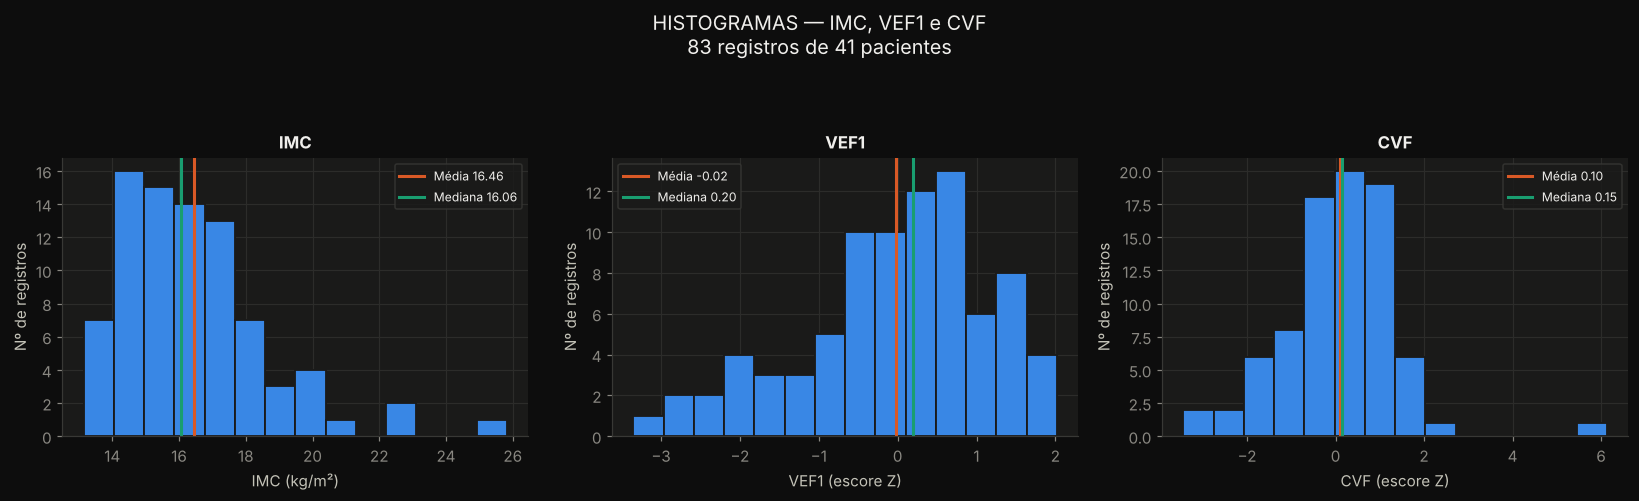

Interpretação:
     IMC: assimetria 1,37; cauda à direita puxa a média (16,46) acima da mediana (16,06).
     VEF1 Z: centrado perto de zero (média -0,02) com cauda para valores muito baixos, onde estão os pacientes com maior comprometimento.
     CVF Z: mesma forma, mas com um valor extremo à direita (6,13) que distorce a escala; é o registro sinalizado como provável erro.


In [7]:
# -- Histogramas ---------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
fig.suptitle(f'HISTOGRAMAS — IMC, VEF1 e CVF\n{len(df)} registros de {df["idpaciente"].nunique()} pacientes', fontsize=13)
for ax, var, rot in zip(axes, ['imc', 'VEF1 Z', 'CVF Z'], ['IMC (kg/m²)', 'VEF1 (escore Z)', 'CVF (escore Z)']):
    s = df[var]
    ax.hist(s, bins=14, color=C['azul'], edgecolor=C['superficie'], linewidth=1.2)
    ax.axvline(s.mean(), color=C['laranja'], lw=2, label=f'Média {s.mean():.2f}')
    ax.axvline(s.median(), color=C['agua'], lw=2, label=f'Mediana {s.median():.2f}')
    ax.set_xlabel(rot); ax.set_ylabel('Nº de registros'); ax.set_title(rot.split(' (')[0])
    ax.legend(fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.9))
mostrar(fig, '01_histogramas')

print('Interpretação:')
print(f"     IMC: assimetria {br(df['imc'].skew())}; cauda à direita puxa a média ({br(df['imc'].mean())}) acima da mediana ({br(df['imc'].median())}).")
print(f"     VEF1 Z: centrado perto de zero (média {br(df['VEF1 Z'].mean())}) com cauda para valores muito baixos, onde estão os pacientes com maior comprometimento.")
print(f"     CVF Z: mesma forma, mas com um valor extremo à direita ({br(df['CVF Z'].max())}) que distorce a escala; é o registro sinalizado como provável erro.")

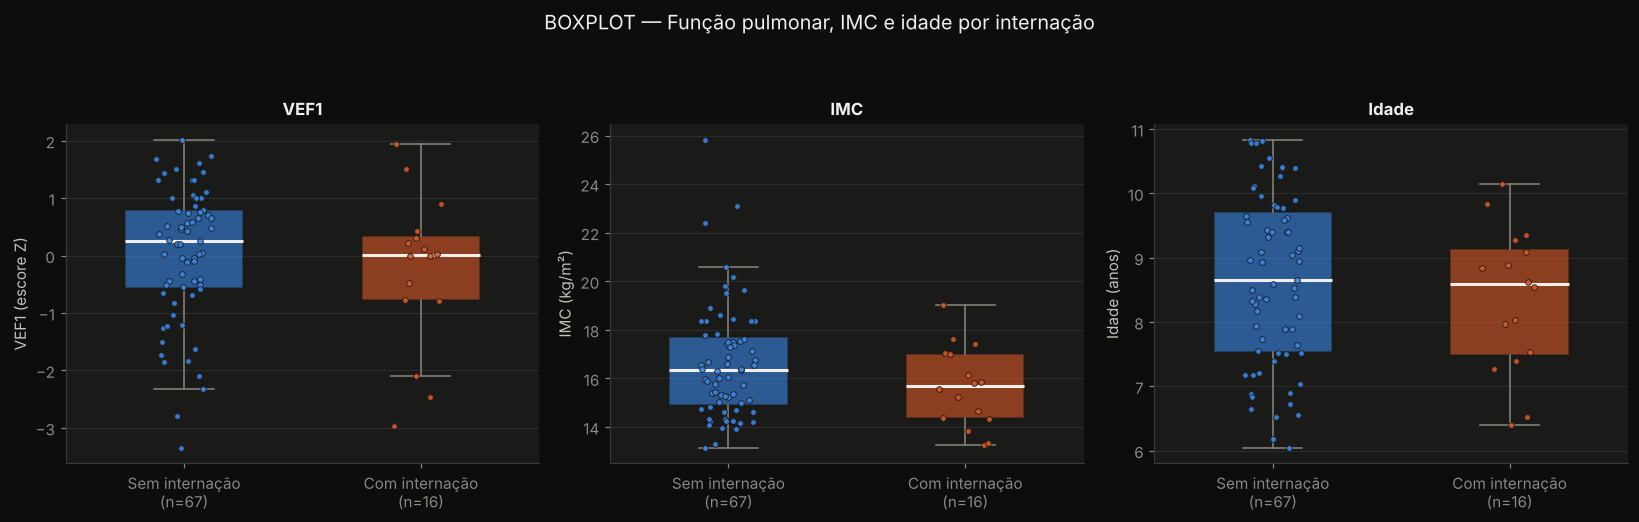

Interpretação:
     As caixas se sobrepõem quase por completo nas três variáveis: a distribuição de função pulmonar, IMC e idade é semelhante com e sem internação, coerente com os p-valores da seção 2.
     Cada ponto é um registro; a dispersão mostra que há pacientes com VEF1 muito baixo sem internação e o contrário.


In [8]:
# -- Boxplots: registros com vs sem internação -------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
grupos_int = [('Sem internação', df[~df['internacao']], C['azul']), ('Com internação', df[df['internacao']], C['laranja'])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
fig.suptitle('BOXPLOT — Função pulmonar, IMC e idade por internação', fontsize=13)
for ax, var, rot in zip(axes, ['VEF1 Z', 'imc', 'idade'], ['VEF1 (escore Z)', 'IMC (kg/m²)', 'Idade (anos)']):
    dados = [g[var].values for _, g, _ in grupos_int]
    bp = ax.boxplot(dados, tick_labels=[f'{n}\n(n={len(g)})' for n, g, _ in grupos_int], patch_artist=True,
                    widths=0.5, showfliers=False,
                    medianprops=dict(color=C['tinta'], lw=2),
                    whiskerprops=dict(color=C['neutro']), capprops=dict(color=C['neutro']))
    for patch, (_, _, cor) in zip(bp['boxes'], grupos_int):
        patch.set_facecolor(cor); patch.set_alpha(0.6); patch.set_edgecolor(C['superficie'])
    for i, (_, g, cor) in enumerate(grupos_int, start=1):
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(g)), g[var], s=14, color=cor, alpha=0.9,
                   edgecolor=C['superficie'], linewidth=0.6, zorder=3)
    ax.set_ylabel(rot); ax.set_title(rot.split(' (')[0])
    ax.grid(axis='x', visible=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '02_boxplot_internacao')

print('Interpretação:')
print('     As caixas se sobrepõem quase por completo nas três variáveis: a distribuição de função pulmonar, IMC e idade '
      'é semelhante com e sem internação, coerente com os p-valores da seção 2.')
print('     Cada ponto é um registro; a dispersão mostra que há pacientes com VEF1 muito baixo sem internação e o contrário.')

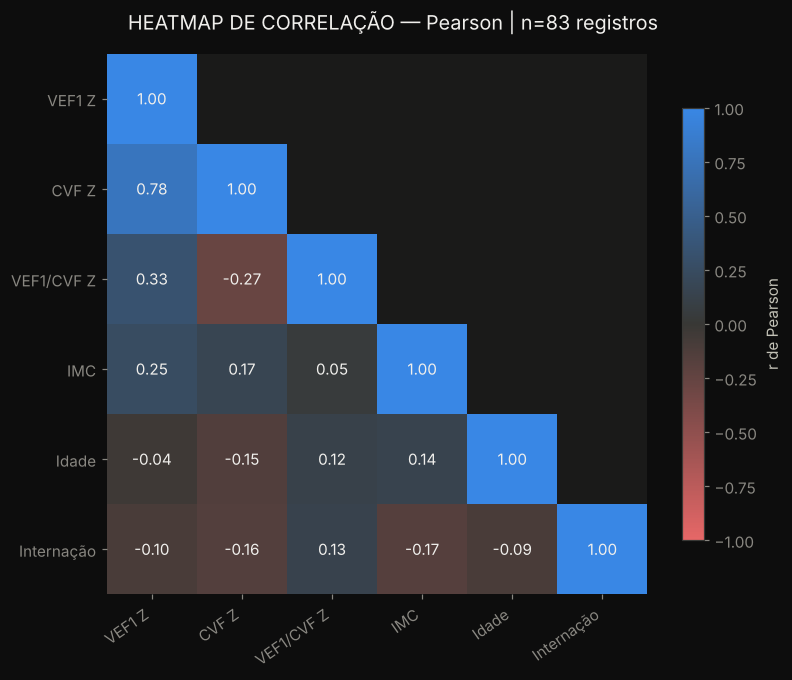

Interpretação — correlações mais fortes entre pares distintos:
      r = +0.78  CVF Z × VEF1 Z
      r = +0.33  VEF1/CVF Z × VEF1 Z
      r = -0.27  VEF1/CVF Z × CVF Z
      r = +0.25  imc × VEF1 Z
Redundâncias: VEF1 Z × VEF1 Predito r = 1.00; VEF1/CVF Z × VEF1/CVF Tile r = 0.97 (medidas derivadas uma da outra; usar só uma delas nos modelos evita colinearidade).
IMC × VEF1 Z: r = +0.25; relação positiva, porém fraca.


In [9]:
# -- Heatmap de correlação ---------------------------------------------------------
vars_c = ['VEF1 Z', 'CVF Z', 'VEF1/CVF Z', 'imc', 'idade', 'internacao_int']
rot_c = ['VEF1 Z', 'CVF Z', 'VEF1/CVF Z', 'IMC', 'Idade', 'Internação']
corr = df[vars_c].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
fig.suptitle(f'HEATMAP DE CORRELAÇÃO — Pearson | n={len(df)} registros', fontsize=13)
mascarado = np.ma.array(corr.values, mask=np.triu(np.ones(corr.shape, dtype=bool), k=1))
im = ax.imshow(mascarado, cmap=CMAP_DIV, vmin=-1, vmax=1)
for i in range(len(vars_c)):
    for j in range(i + 1):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', color=C['tinta'], fontsize=10)
ax.set_xticks(range(len(vars_c))); ax.set_xticklabels(rot_c, rotation=35, ha='right')
ax.set_yticks(range(len(vars_c))); ax.set_yticklabels(rot_c)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='r de Pearson')
fig.tight_layout()
mostrar(fig, '03_correlacao')

pares_corr = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1)).stack()
top = pares_corr.reindex(pares_corr.abs().sort_values(ascending=False).index).head(4)
print('Interpretação — correlações mais fortes entre pares distintos:')
for (a, b), r in top.items():
    print(f"      r = {r:+.2f}  {a} × {b}")
print(f"Redundâncias: VEF1 Z × VEF1 Predito r = {df['VEF1 Z'].corr(df['VEF1 Predito']):.2f}; "
      f"VEF1/CVF Z × VEF1/CVF Tile r = {df['VEF1/CVF Z'].corr(df['VEF1/CVF Tile']):.2f} "
      '(medidas derivadas uma da outra; usar só uma delas nos modelos evita colinearidade).')
print(f"IMC × VEF1 Z: r = {df['imc'].corr(df['VEF1 Z']):+.2f}; relação positiva, porém fraca.")

---
## 4. Regressão Linear

**Pergunta:** o que ajuda a prever a função pulmonar (VEF1 em escore Z)?

Dois modelos contrastam o que um registro "de um dia" entrega frente a um registro **longitudinal**:

| Modelo | Alvo | Preditores | Observações |
|---|---|---|---|
| **A. Transversal** | VEF1 Z no registro | IMC, idade, internação (mesmo registro) | todos os registros |
| **B. Longitudinal** | VEF1 Z no **ano seguinte** | VEF1 Z, IMC, internação e idade do ano atual | pares de anos consecutivos |

**Validação.** Como o mesmo paciente aparece em mais de um registro, um sorteio simples colocaria registros do mesmo paciente no treino e no teste e inflaria o desempenho. Usamos **validação cruzada agrupada por paciente** (5 dobras): cada paciente fica inteiro em treino *ou* em teste, e as métricas vêm das previsões fora da amostra.

**Métricas:** **MAE** (erro médio absoluto, na unidade do alvo), **RMSE** (raiz do erro quadrático médio, penaliza erros grandes) e **R²** (fração da variância explicada; ≤ 0 significa não superar "prever sempre a média").

In [10]:
# -- Funções de avaliação -------------------------------------------------------------
def avaliar_regressao(X, y, grupos, n_splits=5):
    cv = GroupKFold(n_splits=n_splits)
    modelo = make_pipeline(StandardScaler(), LinearRegression())
    pred = cross_val_predict(modelo, X, y, groups=grupos, cv=cv)
    base = cross_val_predict(DummyRegressor(strategy='mean'), X, y, groups=grupos, cv=cv)
    met = lambda yp: dict(MAE=mean_absolute_error(y, yp), RMSE=np.sqrt(mean_squared_error(y, yp)), R2=r2_score(y, yp))
    return pred, met(pred), met(base)

def ols_robusto(X, y, grupos):
    # OLS com preditores padronizados (coef. = efeito de +1 DP) e erro-padrão robusto por paciente
    A = np.column_stack([np.ones(len(X)), ((X - X.mean()) / X.std(ddof=0)).values])
    yv = y.values.astype(float)
    g = np.asarray(grupos)
    inv = np.linalg.inv(A.T @ A)
    beta = inv @ A.T @ yv
    u = yv - A @ beta
    meat = sum(np.outer(A[g == k].T @ u[g == k], A[g == k].T @ u[g == k]) for k in np.unique(g))
    G, (n, k) = len(np.unique(g)), A.shape
    V = inv @ meat @ inv * (G / (G - 1)) * ((n - 1) / (n - k))
    se = np.sqrt(np.diag(V)); t = beta / se; p = 2 * stats.t.sf(np.abs(t), G - 1)
    r2 = 1 - (u @ u) / ((yv - yv.mean()) ** 2).sum()
    tab = pd.DataFrame({'Coef. (por 1 DP)': beta[1:], 'EP robusto': se[1:], 't': t[1:], 'p-valor': p[1:]}, index=X.columns)
    return tab, r2

def nivel_r2(r2):
    if r2 <= 0.05: return 'não supera a previsão pela média'
    if r2 < 0.30:  return 'fraco'
    if r2 < 0.60:  return 'moderado'
    return 'forte'

def pares_consecutivos(d):
    # Une cada registro ao registro do ano seguinte do MESMO paciente (t0 -> t1)
    d = d.sort_values(['idpaciente', 'ano_seguimento']).reset_index(drop=True)
    cols = ['ano_seguimento', 'idade', 'idade_inteira', 'imc', 'internacao_int',
            'VEF1 Z', 'VEF1 Predito', 'CVF Z', 'VEF1/CVF Z']
    prox = d.groupby('idpaciente')[cols].shift(-1)
    ok = (prox['ano_seguimento'] - d['ano_seguimento']) == 1
    a = d.loc[ok, ['idpaciente'] + cols].rename(columns={c: c + '_t0' for c in cols})
    b = prox.loc[ok, cols].rename(columns={c: c + '_t1' for c in cols})
    return pd.concat([a, b], axis=1).reset_index(drop=True)

NOMES = {'imc': 'IMC', 'idade': 'Idade', 'internacao_int': 'Internação',
         'VEF1 Z_t0': 'VEF1 Z (ano atual)', 'imc_t0': 'IMC (ano atual)',
         'internacao_int_t0': 'Internação (ano atual)', 'idade_t0': 'Idade (ano atual)'}

# -- Modelo A: transversal ------------------------------------------------------------
X_A, y_A, g_A = df[['imc', 'idade', 'internacao_int']], df['VEF1 Z'], df['idpaciente']
pred_A, met_A, base_A = avaliar_regressao(X_A, y_A, g_A)
tab_A, r2in_A = ols_robusto(X_A, y_A, g_A)

# -- Modelo B: longitudinal (VEF1 Z do ano seguinte) ---------------------------------
PARES = pares_consecutivos(df)
FEAT_B = ['VEF1 Z_t0', 'imc_t0', 'internacao_int_t0', 'idade_t0']
X_B, y_B, g_B = PARES[FEAT_B], PARES['VEF1 Z_t1'], PARES['idpaciente']
pred_B, met_B, base_B = avaliar_regressao(X_B, y_B, g_B)
tab_B, r2in_B = ols_robusto(X_B, y_B, g_B)
pred_B1, met_B1, _ = avaliar_regressao(PARES[['VEF1 Z_t0']], y_B, g_B)
met_persist = dict(MAE=mean_absolute_error(y_B, PARES['VEF1 Z_t0']),
                   RMSE=np.sqrt(mean_squared_error(y_B, PARES['VEF1 Z_t0'])),
                   R2=r2_score(y_B, PARES['VEF1 Z_t0']))
print(f'Modelo A: {len(df)} registros, {df["idpaciente"].nunique()} pacientes')
print(f'Modelo B: {len(PARES)} pares de anos consecutivos, {PARES["idpaciente"].nunique()} pacientes')

Modelo A: 83 registros, 41 pacientes
Modelo B: 42 pares de anos consecutivos, 39 pacientes


In [11]:
# -- Resultados: coeficientes e métricas ----------------------------------------------
print('=' * 70)
print('  COEFICIENTES (preditores padronizados; EP robusto por paciente)')
print('=' * 70)
print('\nModelo A — VEF1 Z ~ IMC + idade + internação')
display(tab_A.rename(index=NOMES).style.format('{:.3f}'))
print('Modelo B — VEF1 Z (ano seguinte) ~ registro do ano atual')
display(tab_B.rename(index=NOMES).style.format('{:.3f}'))

print('=' * 70)
print('  MÉTRICAS FORA DA AMOSTRA (validação cruzada agrupada por paciente)')
print('=' * 70)
comp = pd.DataFrame([
    {'Modelo': 'A — Transversal (IMC, idade, internação)', 'n': len(y_A), **met_A},
    {'Modelo': 'A — Referência: prever a média', 'n': len(y_A), **base_A},
    {'Modelo': 'B — Longitudinal (4 preditores)', 'n': len(y_B), **met_B},
    {'Modelo': 'B — Só VEF1 Z do ano atual', 'n': len(y_B), **met_B1},
    {'Modelo': 'B — Persistência ingênua (próximo = atual)', 'n': len(y_B), **met_persist},
    {'Modelo': 'B — Referência: prever a média', 'n': len(y_B), **base_B},
]).set_index('Modelo')
comp = comp.rename(columns={'R2': 'R²'})
display(comp.style.format({'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'R²': '{:.3f}'}))

  COEFICIENTES (preditores padronizados; EP robusto por paciente)

Modelo A — VEF1 Z ~ IMC + idade + internação


,Coef. (por 1 DP),EP robusto,t,p-valor
IMC,0.303,0.188,1.611,0.115
Idade,-0.096,0.166,-0.577,0.567
Internação,-0.072,0.125,-0.577,0.567


Modelo B — VEF1 Z (ano seguinte) ~ registro do ano atual


,Coef. (por 1 DP),EP robusto,t,p-valor
VEF1 Z (ano atual),1.063,0.095,11.196,0.000
IMC (ano atual),-0.019,0.073,-0.257,0.799
Internação (ano atual),-0.097,0.097,-0.997,0.325
Idade (ano atual),-0.034,0.063,-0.538,0.594


  MÉTRICAS FORA DA AMOSTRA (validação cruzada agrupada por paciente)


,n,MAE,RMSE,R²
Modelo,,,,
"A — Transversal (IMC, idade, internação)",83,1.035,1.282,-0.164
A — Referência: prever a média,83,0.961,1.220,-0.054
B — Longitudinal (4 preditores),42,0.496,0.630,0.718
B — Só VEF1 Z do ano atual,42,0.456,0.578,0.763
B — Persistência ingênua (próximo = atual),42,0.448,0.569,0.770
B — Referência: prever a média,42,0.946,1.236,-0.086


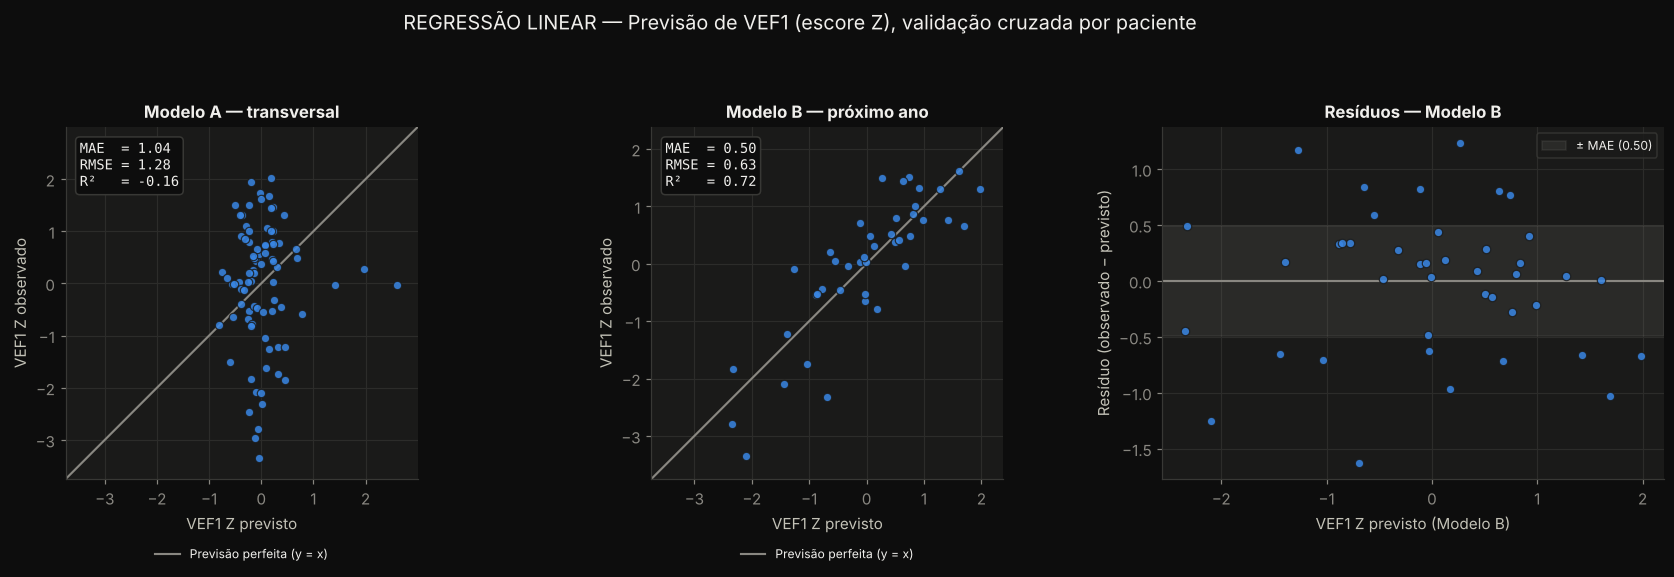

Interpretação:
  Modelo A (transversal): R² fora da amostra = -0,16 → não supera a previsão pela média. MAE 1,04 vs 0,96 da previsão pela média.
     Preditores com p < 0,05: nenhum. Ajuste dentro da amostra: R² = 0,07; o modelo "se ajusta" aos dados que viu, mas não generaliza.
  Modelo B (longitudinal): R² = 0,72 → forte; MAE 0,50 Z (referência pela média: 0,95) e RMSE 0,63.
     Erro típico de ≈ 0,50 desvio-padrão ao prever o VEF1 do ano seguinte, 48% menor que prever pela média.
     Maior efeito: VEF1 Z (ano atual) (coef. +1.06 por DP; p = 0.000).
     O modelo só com VEF1 Z do ano atual (RMSE 0,58) rende praticamente o mesmo que o completo: IMC, internação e idade acrescentam pouco além do próprio histórico pulmonar.
     Não supera a persistência ingênua (RMSE 0,57): repetir o último valor é igualmente bom.
  Leitura para decisão: o valor de um registro está na SÉRIE, não no retrato. Um paciente cujo VEF1 Z de hoje é baixo tende a continuar baixo no ano seguinte, o que permite p

In [12]:
# -- Gráficos: observado vs previsto e resíduos ---------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
fig.suptitle('REGRESSÃO LINEAR — Previsão de VEF1 (escore Z), validação cruzada por paciente', fontsize=13)

for ax, y_, p_, met, tit in [(axes[0], y_A, pred_A, met_A, 'Modelo A — transversal'),
                             (axes[1], y_B, pred_B, met_B, 'Modelo B — próximo ano')]:
    ax.scatter(p_, y_, s=30, color=C['azul'], alpha=0.85, edgecolor=C['superficie'], linewidth=0.8, zorder=3)
    lim = [min(np.min(p_), np.min(y_)) - 0.4, max(np.max(p_), np.max(y_)) + 0.4]
    ax.plot(lim, lim, color=C['neutro'], lw=1.4, label='Previsão perfeita (y = x)')
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('VEF1 Z previsto'); ax.set_ylabel('VEF1 Z observado'); ax.set_title(tit)
    ax.text(0.04, 0.96, f"MAE  = {met['MAE']:.2f}\nRMSE = {met['RMSE']:.2f}\nR²   = {met['R2']:.2f}",
            transform=ax.transAxes, va='top', fontsize=9, family='monospace',
            bbox=dict(boxstyle='round', fc=C['fundo'], ec=C['eixo']))
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), fontsize=8, frameon=False)

res = y_B.values - pred_B
axes[2].scatter(pred_B, res, s=30, color=C['azul'], alpha=0.85, edgecolor=C['superficie'], linewidth=0.8, zorder=3)
axes[2].axhline(0, color=C['neutro'], lw=1.4)
axes[2].axhspan(-met_B['MAE'], met_B['MAE'], color=C['neutro'], alpha=0.15, label=f"± MAE ({met_B['MAE']:.2f})")
axes[2].set_xlabel('VEF1 Z previsto (Modelo B)'); axes[2].set_ylabel('Resíduo (observado − previsto)')
axes[2].set_title('Resíduos — Modelo B'); axes[2].legend(fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '04_regressao_linear')

print('Interpretação:')
print(f"  Modelo A (transversal): R² fora da amostra = {br(met_A['R2'])} → {nivel_r2(met_A['R2'])}. "
      f"MAE {br(met_A['MAE'])} vs {br(base_A['MAE'])} da previsão pela média.")
sig_A = tab_A[tab_A['p-valor'] < 0.05]
print('     Preditores com p < 0,05: ' + (', '.join(NOMES.get(i, i) for i in sig_A.index) if len(sig_A) else 'nenhum') +
      f". Ajuste dentro da amostra: R² = {br(r2in_A)}; o modelo \"se ajusta\" aos dados que viu, mas não generaliza.")
print(f"  Modelo B (longitudinal): R² = {br(met_B['R2'])} → {nivel_r2(met_B['R2'])}; "
      f"MAE {br(met_B['MAE'])} Z (referência pela média: {br(base_B['MAE'])}) e RMSE {br(met_B['RMSE'])}.")
print(f"     Erro típico de ≈ {br(met_B['MAE'])} desvio-padrão ao prever o VEF1 do ano seguinte, "
      f"{br((1 - met_B['MAE'] / base_B['MAE']) * 100, 0)}% menor que prever pela média.")
maior = tab_B['Coef. (por 1 DP)'].abs().idxmax()
print(f"     Maior efeito: {NOMES.get(maior, maior)} (coef. {tab_B.loc[maior, 'Coef. (por 1 DP)']:+.2f} por DP; p = {tab_B.loc[maior, 'p-valor']:.3f}).")
if met_B1['RMSE'] <= met_B['RMSE'] + 0.02:
    print(f"     O modelo só com VEF1 Z do ano atual (RMSE {br(met_B1['RMSE'])}) rende praticamente o mesmo que o completo: "
          'IMC, internação e idade acrescentam pouco além do próprio histórico pulmonar.')
if met_B['RMSE'] < met_persist['RMSE']:
    print(f"     Supera a persistência ingênua (RMSE {br(met_persist['RMSE'])}): vale usar o modelo em vez de apenas repetir o valor atual.")
else:
    print(f"     Não supera a persistência ingênua (RMSE {br(met_persist['RMSE'])}): repetir o último valor é igualmente bom.")
print('  Leitura para decisão: o valor de um registro está na SÉRIE, não no retrato. Um paciente cujo VEF1 Z de hoje é baixo '
      'tende a continuar baixo no ano seguinte, o que permite priorizar acompanhamento antes da consulta.')

---
## 5. Regressão Logística

**Pergunta:** é possível prever, a partir da função pulmonar, do IMC e da idade, se o paciente teve **internação**?

- **Alvo:** `internacao` (1 = sim). A classe positiva é minoritária, então usamos `class_weight='balanced'` para o modelo não aprender a responder "não" sempre.
- **Validação:** validação cruzada estratificada **agrupada por paciente** (mesmo cuidado da seção 4), limiar 0,5.
- **Métricas:** **precisão** (dos alertas, quantos são internações reais), **recall** (das internações reais, quantas o modelo captou) e **F1** (média harmônica das duas), lidos junto com a **matriz de confusão**.
- **Referências honestas:** "alertar para todos" tem precisão = prevalência e recall = 100%; AUC = 0,5 equivale a sorteio.

In [13]:
# -- Dados e validação cruzada ---------------------------------------------------------
FEAT_L = ['VEF1 Z', 'VEF1/CVF Z', 'imc', 'idade']
X_L, y_L, g_L = df[FEAT_L], df['internacao_int'], df['idpaciente']

def proba_cv(seed, n_splits=5):
    modelo = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return cross_val_predict(modelo, X_L, y_L, groups=g_L, cv=cv, method='predict_proba')[:, 1]

proba = proba_cv(RANDOM_STATE)
pred_L = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_L, pred_L).ravel()
prev = y_L.mean()
met_L = dict(Acurácia=accuracy_score(y_L, pred_L), Precisão=precision_score(y_L, pred_L, zero_division=0),
             Recall=recall_score(y_L, pred_L), F1=f1_score(y_L, pred_L), AUC=roc_auc_score(y_L, proba))
todos = dict(Acurácia=prev, Precisão=prev, Recall=1.0, F1=2 * prev / (1 + prev), AUC=0.5)

print('=' * 70)
print('  REGRESSÃO LOGÍSTICA — internação (validação cruzada agrupada, limiar 0,5)')
print('=' * 70)
print(f'Prevalência de internação: {y_L.sum()} de {len(y_L)} registros ({prev * 100:.1f}%)')
cm_df = pd.DataFrame([[tn, fp], [fn, tp]], index=['Real: sem internação', 'Real: com internação'],
                     columns=['Previsto: sem', 'Previsto: com'])
display(cm_df)
resumo = pd.DataFrame({'Modelo': met_L, 'Alertar para todos': todos}).T
display(resumo.style.format('{:.3f}'))

  REGRESSÃO LOGÍSTICA — internação (validação cruzada agrupada, limiar 0,5)
Prevalência de internação: 16 de 83 registros (19.3%)


,Previsto: sem,Previsto: com
Real: sem internação,42,25
Real: com internação,7,9


,Acurácia,Precisão,Recall,F1,AUC
Modelo,0.614,0.265,0.562,0.360,0.547
Alertar para todos,0.193,0.193,1.000,0.323,0.500


In [14]:
# -- Estabilidade (20 repetições) e razões de chance ---------------------------------------
rep = []
for seed in range(20):
    pr = proba_cv(seed)
    pd_ = (pr >= 0.5).astype(int)
    rep.append(dict(Precisão=precision_score(y_L, pd_, zero_division=0), Recall=recall_score(y_L, pd_),
                    F1=f1_score(y_L, pd_), AUC=roc_auc_score(y_L, pr)))
rep = pd.DataFrame(rep)
est = pd.DataFrame({'Média': rep.mean(), 'DP': rep.std(), 'Mín': rep.min(), 'Máx': rep.max()})
print('Estabilidade: 20 sorteios diferentes de dobras')
display(est.style.format('{:.3f}'))

# Razões de chance (modelo sem ponderação), IC 95% por bootstrap de pacientes
Xs = ((X_L - X_L.mean()) / X_L.std(ddof=0)).values
yv = y_L.values
pacientes = df['idpaciente'].unique()
idx_pac = {p: np.where(df['idpaciente'].values == p)[0] for p in pacientes}
def ajustar_or(idx):
    return np.exp(LogisticRegression(C=1e6, max_iter=2000).fit(Xs[idx], yv[idx]).coef_[0])

or_base = ajustar_or(np.arange(len(df)))
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(500):
    amostra = rng.choice(pacientes, size=len(pacientes), replace=True)
    idx = np.concatenate([idx_pac[p] for p in amostra])
    if 0 < yv[idx].sum() < len(idx):
        boot.append(ajustar_or(idx))
lo, hi = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
or_df = pd.DataFrame({'Razão de chance (por +1 DP)': or_base, 'IC95% inf.': lo, 'IC95% sup.': hi}, index=FEAT_L)
or_df['IC inclui 1?'] = np.where((lo <= 1) & (hi >= 1), 'sim', 'não')
print('Razões de chance (IC 95% por bootstrap de pacientes)')
display(or_df.style.format({'Razão de chance (por +1 DP)': '{:.2f}', 'IC95% inf.': '{:.2f}', 'IC95% sup.': '{:.2f}'}))

Estabilidade: 20 sorteios diferentes de dobras


,Média,DP,Mín,Máx
Precisão,0.270,0.032,0.211,0.345
Recall,0.578,0.045,0.500,0.625
F1,0.368,0.036,0.296,0.444
AUC,0.556,0.035,0.488,0.619


Razões de chance (IC 95% por bootstrap de pacientes)


,Razão de chance (por +1 DP),IC95% inf.,IC95% sup.,IC inclui 1?
VEF1 Z,0.75,0.31,1.74,sim
VEF1/CVF Z,1.62,0.85,4.86,sim
imc,0.66,0.25,1.23,sim
idade,0.78,0.39,1.48,sim


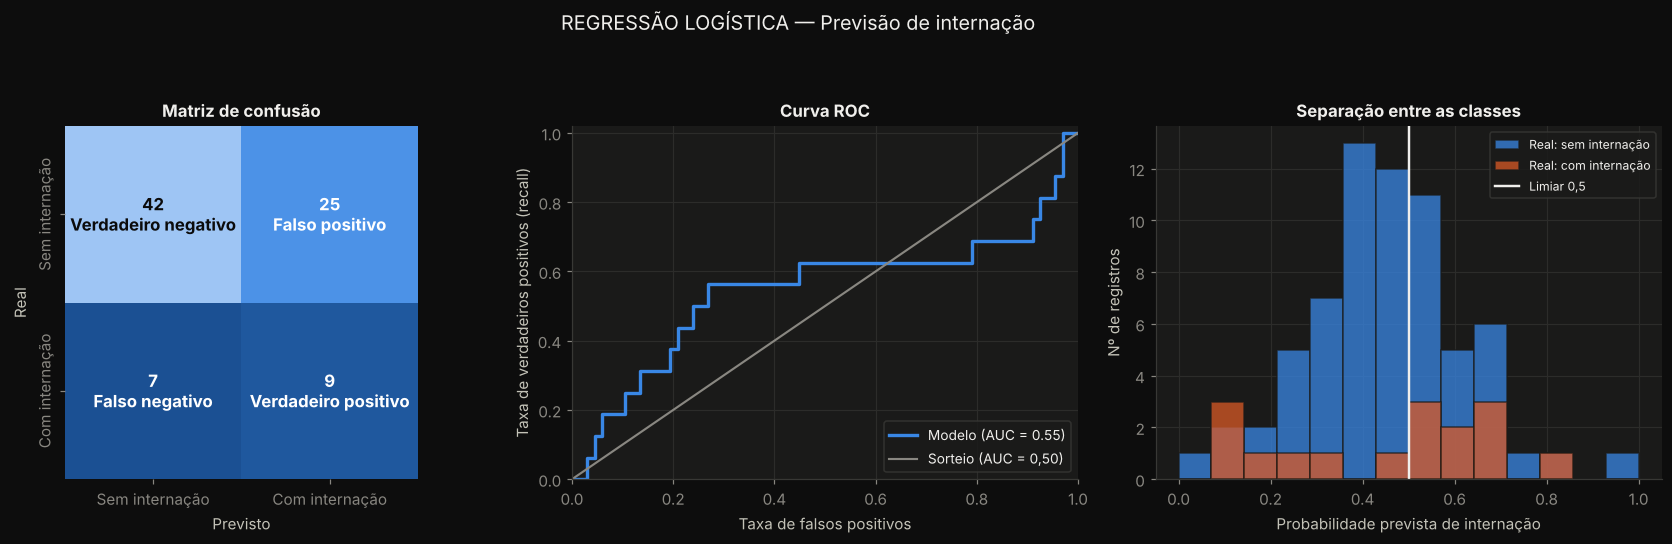

Interpretação:
  Matriz: 9 internações captadas (VP), 7 perdidas (FN), 25 alertas falsos (FP) e 42 corretos sem internação (VN).
  Precisão 0,26: de cada 100 alertas, cerca de 26 são internações reais (a prevalência é 19%).
  Recall 0,56: o modelo capta 56% das internações. F1 = 0,36.
  Em 20 repetições: F1 = 0,37 ± 0,04 e AUC = 0,56 ± 0,03.
  Referência trivial (alertar para todos): precisão 0,19, recall 1,00 e F1 0,32. O F1 do modelo (0,36) é só marginalmente melhor, mas a AUC de 0,55 é próxima de 0,5 (sorteio): o ganho vem de trocar recall por alertas, não de discriminar de fato quem será internado.
  Todos os IC 95% das razões de chance incluem 1: nenhuma variável, isolada, altera de forma confiável a chance de internação.
  Leitura para decisão: função pulmonar, IMC e idade NÃO bastam para prever internação nesta base. Isso é um resultado útil: indica quais dados o registro precisa passar a coletar (exacerbações, microbiologia, adesão, fatores sociais) e que é preciso mais pacient

In [15]:
# -- Gráficos: matriz de confusão, ROC e distribuição das probabilidades --------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('REGRESSÃO LOGÍSTICA — Previsão de internação', fontsize=13)

cm = np.array([[tn, fp], [fn, tp]])
axes[0].imshow(cm, cmap=CMAP_SEQ, vmin=0)
rot_cm = [['Verdadeiro negativo', 'Falso positivo'], ['Falso negativo', 'Verdadeiro positivo']]
for i in range(2):
    for j in range(2):
        cor = '#0b0b0b' if cm[i, j] > 0.6 * cm.max() else '#ffffff'
        axes[0].text(j, i, f'{cm[i, j]}\n{rot_cm[i][j]}', ha='center', va='center', color=cor, fontsize=11, fontweight='bold')
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(['Sem internação', 'Com internação'])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(['Sem internação', 'Com internação'], rotation=90, va='center')
axes[0].set_xlabel('Previsto'); axes[0].set_ylabel('Real'); axes[0].set_title('Matriz de confusão')
axes[0].grid(False)
for sp in axes[0].spines.values():
    sp.set_visible(False)

fpr, tpr, _ = roc_curve(y_L, proba)
axes[1].plot(fpr, tpr, color=C['azul'], lw=2.2, label=f"Modelo (AUC = {met_L['AUC']:.2f})")
axes[1].plot([0, 1], [0, 1], color=C['neutro'], lw=1.4, label='Sorteio (AUC = 0,50)')
axes[1].set_xlabel('Taxa de falsos positivos'); axes[1].set_ylabel('Taxa de verdadeiros positivos (recall)')
axes[1].set_title('Curva ROC'); axes[1].legend(loc='lower right', fontsize=9)
axes[1].set_xlim(0, 1); axes[1].set_ylim(0, 1.02)

bins = np.linspace(0, 1, 15)
axes[2].hist(proba[y_L == 0], bins=bins, color=C['azul'], alpha=0.75, edgecolor=C['superficie'], label='Real: sem internação')
axes[2].hist(proba[y_L == 1], bins=bins, color=C['laranja'], alpha=0.75, edgecolor=C['superficie'], label='Real: com internação')
axes[2].axvline(0.5, color=C['tinta'], lw=1.6, label='Limiar 0,5')
axes[2].set_xlabel('Probabilidade prevista de internação'); axes[2].set_ylabel('Nº de registros')
axes[2].set_title('Separação entre as classes'); axes[2].legend(fontsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '05_regressao_logistica')

print('Interpretação:')
print(f"  Matriz: {tp} internações captadas (VP), {fn} perdidas (FN), {fp} alertas falsos (FP) e {tn} corretos sem internação (VN).")
print(f"  Precisão {br(met_L['Precisão'])}: de cada 100 alertas, cerca de {met_L['Precisão'] * 100:.0f} são internações reais "
      f"(a prevalência é {prev * 100:.0f}%).")
print(f"  Recall {br(met_L['Recall'])}: o modelo capta {met_L['Recall'] * 100:.0f}% das internações. F1 = {br(met_L['F1'])}.")
print(f"  Em 20 repetições: F1 = {br(est.loc['F1', 'Média'])} ± {br(est.loc['F1', 'DP'])} e AUC = {br(est.loc['AUC', 'Média'])} ± {br(est.loc['AUC', 'DP'])}.")
if met_L['AUC'] < 0.6:
    print(f"  Referência trivial (alertar para todos): precisão {br(todos['Precisão'])}, recall 1,00 e F1 {br(todos['F1'])}. "
          f"O F1 do modelo ({br(met_L['F1'])}) é só marginalmente melhor, mas a AUC de {br(met_L['AUC'])} é próxima de 0,5 (sorteio): "
          'o ganho vem de trocar recall por alertas, não de discriminar de fato quem será internado.')
if (or_df['IC inclui 1?'] == 'sim').all():
    print('  Todos os IC 95% das razões de chance incluem 1: nenhuma variável, isolada, altera de forma confiável a chance de internação.')
print('  Leitura para decisão: função pulmonar, IMC e idade NÃO bastam para prever internação nesta base. Isso é um resultado útil: '
      'indica quais dados o registro precisa passar a coletar (exacerbações, microbiologia, adesão, fatores sociais) e que é preciso mais pacientes.')

---
## 6. O Tratamento Funcionou? Aos 6 Anos vs 1 Ano Depois

**Desenho:** comparação **pareada** do mesmo paciente aos 6 anos e 1 ano depois (7 anos). A idade usa a data de referência definida na seção 1.

| Critério de sucesso | Métrica | Regra no nível da coorte | Regra por paciente |
|---|---|---|---|
| 1. IMC melhora ou estabiliza | Δ IMC (7 − 6 anos) | **mediana** do Δ ≥ −0,5 kg/m² | Δ ≥ −0,5 kg/m² |
| 2. Internações diminuem | % de pacientes internados | taxa aos 7 anos **menor** que aos 6 | sem internação aos 7 anos |
| 3. Função pulmonar melhora | Δ VEF1 (escore Z) | **mediana** do Δ > 0 | Δ VEF1 Z > 0 |

Testes de apoio: Wilcoxon pareado (IMC, VEF1) e McNemar exato (internação). Não são condição de sucesso, servem para dizer **quanto confiar** em cada resultado.

> **Atenção ao desenho:** a base não contém a variável de tratamento nem grupo controle. O que se mede é a **evolução da coorte acompanhada**, não o efeito causal de uma intervenção.

In [16]:
# -- Coorte 6 → 7 anos --------------------------------------------------------------------
CLASSE_COR = {'melhora': C['bom'], 'estável': C['neutro'], 'piora': C['critico']}

def classificar(delta, tol=0.0):
    return np.where(delta > tol, 'melhora', np.where(delta < -tol, 'piora', 'estável'))

def p_wilcoxon(x1, x0):
    try:
        return stats.wilcoxon(x1, x0).pvalue
    except ValueError:
        return np.nan

def selecionar_coorte(pares, idade_base=IDADE_BASE):
    return pares[(pares['idade_inteira_t0'] == idade_base) &
                 (pares['idade_inteira_t1'] == idade_base + 1)].reset_index(drop=True)

def avaliar_coorte(P, tol_imc=TOL_IMC):
    d_imc = P['imc_t1'] - P['imc_t0']
    d_vef = P['VEF1 Z_t1'] - P['VEF1 Z_t0']
    i0, i1 = P['internacao_int_t0'], P['internacao_int_t1']
    b = int(((i0 == 1) & (i1 == 0)).sum()); c = int(((i0 == 0) & (i1 == 1)).sum())
    R = dict(n=len(P), pacientes=P['idpaciente'].nunique(),
             med_d_imc=d_imc.median(), pct_imc_ok=(d_imc >= -tol_imc).mean(), p_imc=p_wilcoxon(P['imc_t1'], P['imc_t0']),
             taxa_t0=i0.mean(), taxa_t1=i1.mean(), reduziu=b, passou_a_internar=c,
             p_int=stats.binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0,
             med_d_vef=d_vef.median(), media_d_vef=d_vef.mean(), pct_vef_melhora=(d_vef > 0).mean(),
             p_vef=p_wilcoxon(P['VEF1 Z_t1'], P['VEF1 Z_t0']),
             corr_rm=np.corrcoef(P['VEF1 Z_t0'], d_vef)[0, 1])
    R['imc_ok'] = R['med_d_imc'] >= -tol_imc
    R['int_ok'] = R['taxa_t1'] < R['taxa_t0']
    R['vef_ok'] = R['med_d_vef'] > 0
    R['criterios'] = int(R['imc_ok']) + int(R['int_ok']) + int(R['vef_ok'])
    return R

COORTE = selecionar_coorte(PARES)
R = avaliar_coorte(COORTE)
print(f'Coorte: {R["n"]} pacientes com registro aos {IDADE_BASE} anos e no ano seguinte (aos {IDADE_POS}).')
print(f'Pacientes: {list(COORTE["idpaciente"])}')

VARS_PP = {'imc': 'IMC (kg/m²)', 'VEF1 Z': 'VEF1 (Z)', 'VEF1 Predito': 'VEF1 (% predito)',
           'CVF Z': 'CVF (Z)', 'VEF1/CVF Z': 'VEF1/CVF (Z)'}
rows = []
for v, rot in VARS_PP.items():
    a, b = COORTE[v + '_t0'], COORTE[v + '_t1']
    d = b - a
    rows.append({'Variável': rot, f'Média {IDADE_BASE} anos': a.mean(), f'Média {IDADE_POS} anos': b.mean(),
                 'Δ média': d.mean(), 'Δ mediana': d.median(), 'Pacientes que melhoraram': f'{int((d > 0).sum())}/{len(d)}',
                 'Wilcoxon p': p_wilcoxon(b, a)})
pp_df = pd.DataFrame(rows).set_index('Variável')
display(pp_df.style.format({c: '{:.2f}' for c in pp_df.columns if c not in ['Pacientes que melhoraram', 'Wilcoxon p']} | {'Wilcoxon p': '{:.3f}'}))

Coorte: 10 pacientes com registro aos 6 anos e no ano seguinte (aos 7).
Pacientes: ['5ygm1-8', '5ygom-0', '5ygv8-7', 'hv4tb-2', 'hv4wg-3', 'hv4zk-6', 'ntgnf-7', 'ntgq8-3', 'ntgu0-3', 'trszz-3']


,Média 6 anos,Média 7 anos,Δ média,Δ mediana,Pacientes que melhoraram,Wilcoxon p
Variável,,,,,,
IMC (kg/m²),15.73,16.16,0.43,0.30,6/10,0.160
VEF1 (Z),0.31,0.45,0.14,0.30,8/10,0.391
VEF1 (% predito),103.78,105.56,1.78,3.62,8/10,0.375
CVF (Z),0.38,0.57,0.18,0.17,6/10,0.557
VEF1/CVF (Z),-0.02,-0.22,-0.20,0.08,5/10,0.820


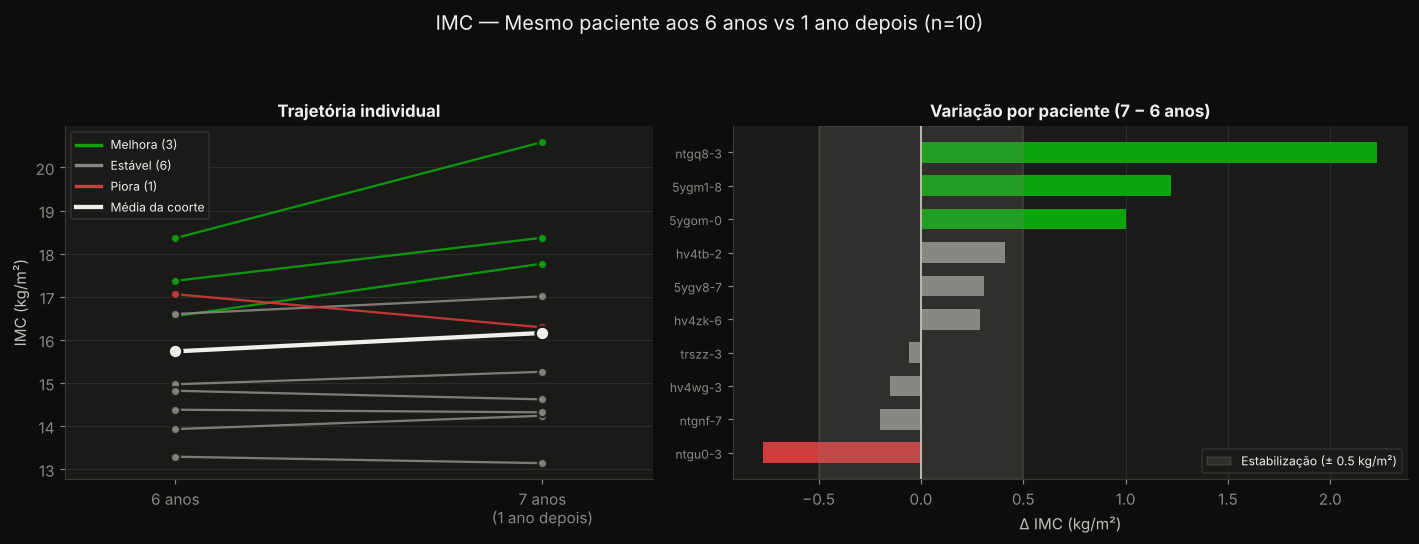

Interpretação:
     IMC: 3 melhoraram, 6 ficaram estáveis (dentro de ±0,5 kg/m²) e 1 piorou. Mediana do Δ = 0,30 kg/m²; 90% dos pacientes atendem ao critério (melhora ou estabilização).
     Cuidado: o IMC sobe naturalmente com o crescimento. A base não traz IMC em percentil/escore Z para a idade, então "melhora" aqui inclui o ganho esperado da idade.


In [17]:
# -- Gráfico 1: IMC aos 6 anos vs 1 ano depois ------------------------------------------
def painel_pareado(ax, a, b, titulo, ylabel, tol=0.0):
    delta = b - a
    classes = classificar(delta, tol)
    for x0, x1, cl in zip(a, b, classes):
        ax.plot([0, 1], [x0, x1], color=CLASSE_COR[cl], lw=1.5, alpha=0.9, marker='o', ms=6,
                mec=C['superficie'], mew=1.4, zorder=3)
    ax.plot([0, 1], [a.mean(), b.mean()], color=C['tinta'], lw=2.8, marker='o', ms=9,
            mec=C['superficie'], mew=1.6, zorder=5)
    ax.set_xticks([0, 1]); ax.set_xticklabels([f'{IDADE_BASE} anos', f'{IDADE_POS} anos\n(1 ano depois)'])
    ax.set_xlim(-0.3, 1.3); ax.set_title(titulo); ax.set_ylabel(ylabel)
    ax.grid(axis='x', visible=False)
    h = [Line2D([0], [0], color=CLASSE_COR[k], lw=2.2, label=f'{k.capitalize()} ({int((classes == k).sum())})')
         for k in ['melhora', 'estável', 'piora'] if (classes == k).any()]
    h.append(Line2D([0], [0], color=C['tinta'], lw=2.8, label='Média da coorte'))
    ax.legend(handles=h, fontsize=8, loc='best')
    return classes

def painel_delta(ax, ids, delta, classes, titulo, xlabel, tol=0.0):
    ordem = np.argsort(delta)
    ax.barh(range(len(delta)), delta[ordem], color=[CLASSE_COR[c] for c in classes[ordem]], height=0.62)
    ax.axvline(0, color=C['tinta2'], lw=1.2)
    if tol > 0:
        ax.axvspan(-tol, tol, color=C['neutro'], alpha=0.2, label=f'Estabilização (± {tol} kg/m²)')
        ax.legend(fontsize=8, loc='lower right')
    ax.set_yticks(range(len(delta))); ax.set_yticklabels(np.array(ids)[ordem], fontsize=8)
    ax.set_xlabel(xlabel); ax.set_title(titulo)
    ax.grid(axis='y', visible=False)

ids = COORTE['idpaciente'].values
a_imc, b_imc = COORTE['imc_t0'].values, COORTE['imc_t1'].values
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.15]})
fig.suptitle(f'IMC — Mesmo paciente aos {IDADE_BASE} anos vs 1 ano depois (n={len(COORTE)})', fontsize=13)
cls_imc = painel_pareado(axes[0], a_imc, b_imc, 'Trajetória individual', 'IMC (kg/m²)', tol=TOL_IMC)
painel_delta(axes[1], ids, b_imc - a_imc, cls_imc, 'Variação por paciente (7 − 6 anos)', 'Δ IMC (kg/m²)', tol=TOL_IMC)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '06_imc_6_vs_7')

n_m, n_e, n_p = [int((cls_imc == k).sum()) for k in ['melhora', 'estável', 'piora']]
print('Interpretação:')
print(f"     IMC: {n_m} melhoraram, {n_e} ficaram estáveis (dentro de ±{br(TOL_IMC, 1)} kg/m²) e {n_p} {'piorou' if n_p == 1 else 'pioraram'}. "
      f"Mediana do Δ = {br(R['med_d_imc'])} kg/m²; {R['pct_imc_ok'] * 100:.0f}% dos pacientes atendem ao critério (melhora ou estabilização).")
print('     Cuidado: o IMC sobe naturalmente com o crescimento. A base não traz IMC em percentil/escore Z para a idade, '
      'então "melhora" aqui inclui o ganho esperado da idade.')

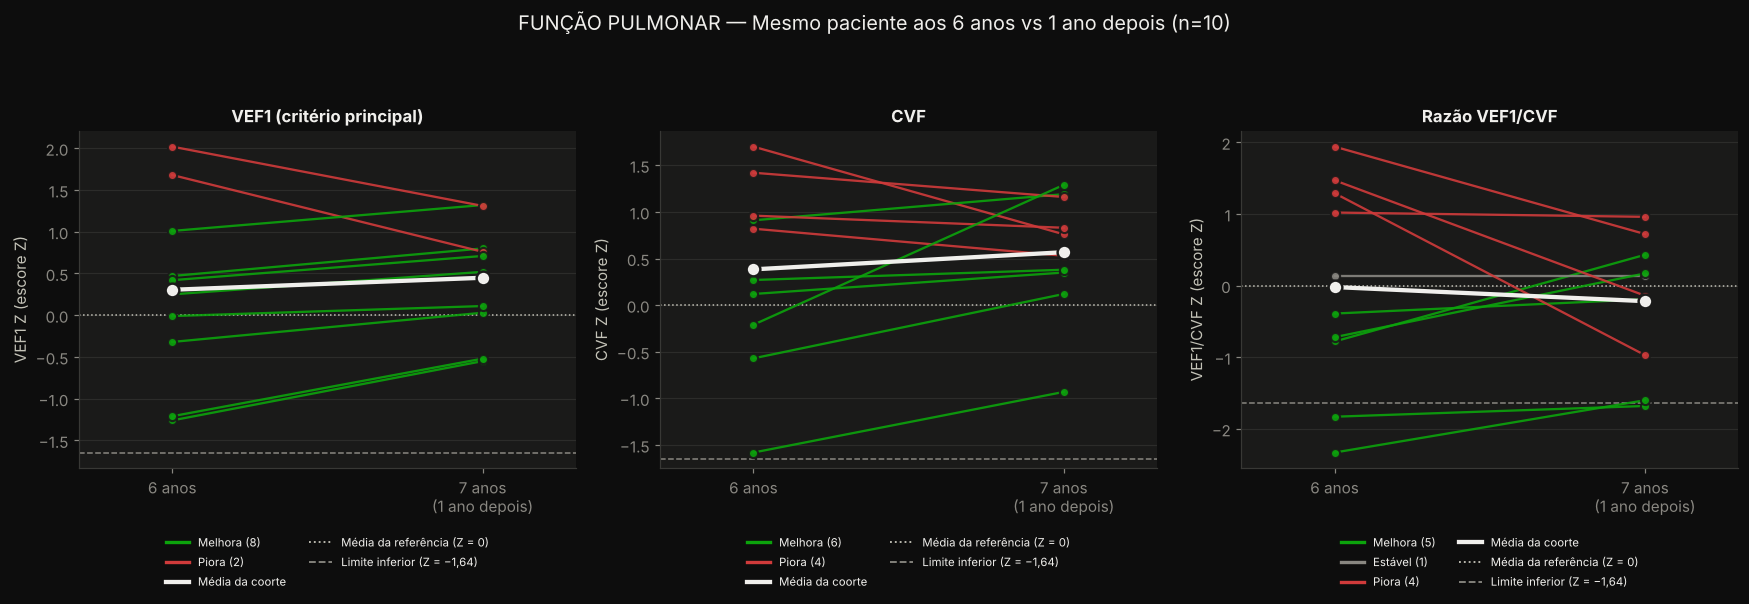

Interpretação:
     VEF1 Z: 8 de 10 pacientes melhoraram; mediana do Δ = 0,30 Z (Wilcoxon p = 0,391).
     Correlação entre VEF1 Z inicial e a variação = -0,87: os pacientes que começaram mais baixos subiram e os que começaram mais altos caíram. Esse padrão é típico de REGRESSÃO À MÉDIA e pode explicar parte da "melhora".
     CVF e razão VEF1/CVF são desfechos secundários: melhoraram em 6 e 5 pacientes, respectivamente.


In [18]:
# -- Gráfico 2: função pulmonar aos 6 anos vs 1 ano depois ---------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8))
fig.suptitle(f'FUNÇÃO PULMONAR — Mesmo paciente aos {IDADE_BASE} anos vs 1 ano depois (n={len(COORTE)})', fontsize=13)
cls_pulm = {}
for ax, v, tit in zip(axes, ['VEF1 Z', 'CVF Z', 'VEF1/CVF Z'],
                      ['VEF1 (critério principal)', 'CVF', 'Razão VEF1/CVF']):
    cls_pulm[v] = painel_pareado(ax, COORTE[v + '_t0'].values, COORTE[v + '_t1'].values, tit, f'{v} (escore Z)')
    ax.axhline(0, color=C['tinta2'], lw=1.0, ls=':', zorder=1)
    ax.axhline(LIN_Z, color=C['neutro'], lw=1.0, ls='--', zorder=1)
    ax.legend(handles=ax.get_legend().legend_handles + [
        Line2D([0], [0], color=C['tinta2'], lw=1.2, ls=':', label='Média da referência (Z = 0)'),
        Line2D([0], [0], color=C['neutro'], lw=1.2, ls='--', label='Limite inferior (Z = −1,64)')],
        fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '07_funcao_pulmonar_6_vs_7')

c = cls_pulm['VEF1 Z']
print('Interpretação:')
print(f"     VEF1 Z: {int((c == 'melhora').sum())} de {len(c)} pacientes melhoraram; mediana do Δ = {br(R['med_d_vef'])} Z "
      f"(Wilcoxon p = {br(R['p_vef'], 3)}).")
print(f"     Correlação entre VEF1 Z inicial e a variação = {br(R['corr_rm'])}: os pacientes que começaram mais baixos subiram e os que começaram mais altos caíram. "
      + ('Esse padrão é típico de REGRESSÃO À MÉDIA e pode explicar parte da \"melhora\".' if R['corr_rm'] < -0.5 else 'Sem sinal forte de regressão à média.'))
print(f"     CVF e razão VEF1/CVF são desfechos secundários: melhoraram em {int((cls_pulm['CVF Z'] == 'melhora').sum())} e {int((cls_pulm['VEF1/CVF Z'] == 'melhora').sum())} pacientes, respectivamente.")

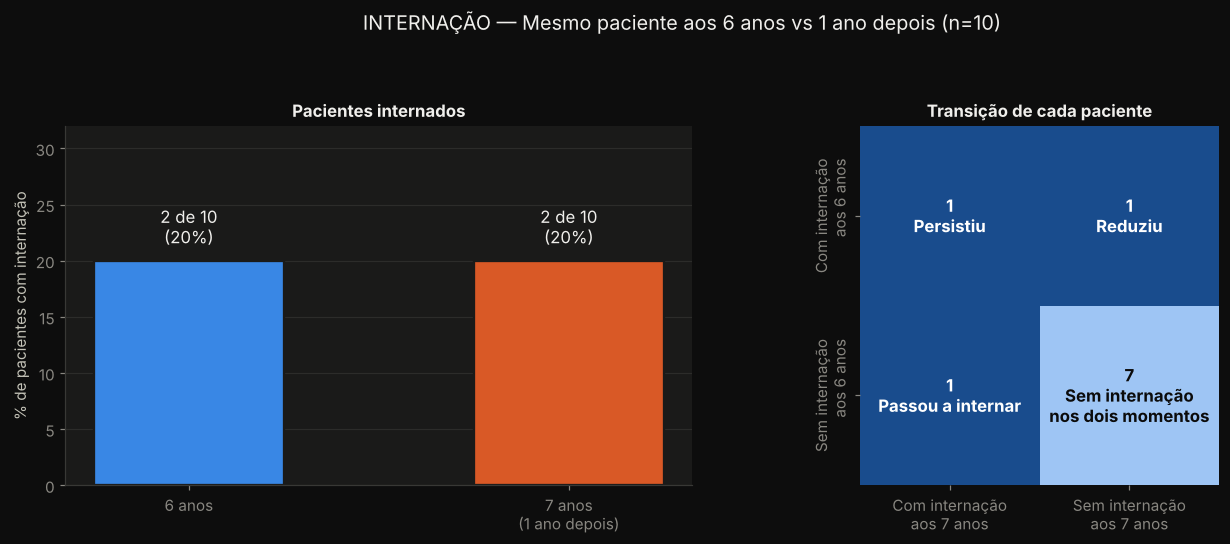

Interpretação:
     Taxa de internação: 20% aos 6 anos → 20% aos 7 anos. 1 paciente(s) deixaram de ser internados e 1 passaram a ser (McNemar exato p = 1,00).
     Internação é um evento episódico: com poucos eventos, a diferença de um único paciente move a taxa em 10 pontos percentuais.


In [19]:
# -- Gráfico 3: internação aos 6 anos vs 1 ano depois ------------------------------------------
n = len(COORTE)
i0, i1 = COORTE['internacao_int_t0'], COORTE['internacao_int_t1']
c0, c1 = int(i0.sum()), int(i1.sum())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
fig.suptitle(f'INTERNAÇÃO — Mesmo paciente aos {IDADE_BASE} anos vs 1 ano depois (n={n})', fontsize=13)

rot_x = [f'{IDADE_BASE} anos', f'{IDADE_POS} anos\n(1 ano depois)']
barras = axes[0].bar(rot_x, [c0 / n * 100, c1 / n * 100], color=[C['azul'], C['laranja']], width=0.5,
                     edgecolor=C['superficie'], linewidth=1.5)
for brr, cc in zip(barras, [c0, c1]):
    axes[0].text(brr.get_x() + brr.get_width() / 2, brr.get_height() + 1.2, f'{cc} de {n}\n({cc / n * 100:.0f}%)',
                 ha='center', va='bottom', color=C['tinta'], fontsize=11)
axes[0].set_ylim(0, max(max(c0, c1) / n * 100 * 1.6, 30))
axes[0].set_ylabel('% de pacientes com internação'); axes[0].set_title('Pacientes internados')
axes[0].grid(axis='x', visible=False)

M = pd.crosstab(i0, i1).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values
axes[1].imshow(M, cmap=CMAP_SEQ, vmin=0, vmax=max(M.max(), 1))
rot_t = [['Persistiu', 'Reduziu'], ['Passou a internar', 'Sem internação\nnos dois momentos']]
for i in range(2):
    for j in range(2):
        cor = '#0b0b0b' if M[i, j] > 0.6 * max(M.max(), 1) else '#ffffff'
        axes[1].text(j, i, f'{M[i, j]}\n{rot_t[i][j]}', ha='center', va='center', color=cor, fontsize=11, fontweight='bold')
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels([f'Com internação\naos {IDADE_POS} anos', f'Sem internação\naos {IDADE_POS} anos'])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels([f'Com internação\naos {IDADE_BASE} anos', f'Sem internação\naos {IDADE_BASE} anos'], rotation=90, va='center')
axes[1].set_title('Transição de cada paciente'); axes[1].grid(False)
for sp in axes[1].spines.values():
    sp.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
mostrar(fig, '08_internacao_6_vs_7')

print('Interpretação:')
print(f"     Taxa de internação: {R['taxa_t0'] * 100:.0f}% aos {IDADE_BASE} anos → {R['taxa_t1'] * 100:.0f}% aos {IDADE_POS} anos. "
      f"{R['reduziu']} paciente(s) deixaram de ser internados e {R['passou_a_internar']} passaram a ser (McNemar exato p = {br(R['p_int'], 2)}).")
print('     Internação é um evento episódico: com poucos eventos, a diferença de um único paciente move a taxa em 10 pontos percentuais.')

In [20]:
# -- Veredito: critérios de sucesso no nível da coorte -------------------------------------------
def rot_status(delta, tol=0.0):
    return 'melhora' if delta > tol else ('piora' if delta < -tol else 'estabilização')

tab_v = pd.DataFrame([
    {'Critério': '1. IMC melhora ou estabiliza', 'Métrica': 'IMC médio (kg/m²)',
     f'{IDADE_BASE} anos': f"{COORTE['imc_t0'].mean():.2f}", f'{IDADE_POS} anos': f"{COORTE['imc_t1'].mean():.2f}",
     'Variação (mediana)': f"{R['med_d_imc']:+.2f}", 'Resultado': rot_status(R['med_d_imc'], TOL_IMC),
     'Atendido': '✔ Sim' if R['imc_ok'] else '✘ Não', 'Evidência': f"Wilcoxon p = {R['p_imc']:.2f}"},
    {'Critério': '2. Internações diminuem', 'Métrica': '% de pacientes internados',
     f'{IDADE_BASE} anos': f"{R['taxa_t0'] * 100:.0f}%", f'{IDADE_POS} anos': f"{R['taxa_t1'] * 100:.0f}%",
     'Variação (mediana)': f"{(R['taxa_t1'] - R['taxa_t0']) * 100:+.0f} p.p.",
     'Resultado': 'diminuição' if R['int_ok'] else ('aumento' if R['taxa_t1'] > R['taxa_t0'] else 'sem mudança'),
     'Atendido': '✔ Sim' if R['int_ok'] else '✘ Não', 'Evidência': f"McNemar exato p = {R['p_int']:.2f}"},
    {'Critério': '3. Função pulmonar melhora', 'Métrica': 'VEF1 (escore Z) médio',
     f'{IDADE_BASE} anos': f"{COORTE['VEF1 Z_t0'].mean():.2f}", f'{IDADE_POS} anos': f"{COORTE['VEF1 Z_t1'].mean():.2f}",
     'Variação (mediana)': f"{R['med_d_vef']:+.2f}", 'Resultado': rot_status(R['med_d_vef']),
     'Atendido': '✔ Sim' if R['vef_ok'] else '✘ Não', 'Evidência': f"Wilcoxon p = {R['p_vef']:.2f}"},
]).set_index('Critério')
print('=' * 70)
print(f'  VEREDITO — {R["n"]} pacientes, dos {IDADE_BASE} aos {IDADE_POS} anos')
print('=' * 70)
display(tab_v)
print(f"Critérios atendidos no nível da coorte: {R['criterios']} de 3.")

  VEREDITO — 10 pacientes, dos 6 aos 7 anos


,Métrica,6 anos,7 anos,Variação (mediana),Resultado,Atendido,Evidência
Critério,,,,,,,
1. IMC melhora ou estabiliza,IMC médio (kg/m²),15.73,16.16,+0.30,estabilização,✔ Sim,Wilcoxon p = 0.16
2. Internações diminuem,% de pacientes internados,20%,20%,+0 p.p.,sem mudança,✘ Não,McNemar exato p = 1.00
3. Função pulmonar melhora,VEF1 (escore Z) médio,0.31,0.45,+0.30,melhora,✔ Sim,Wilcoxon p = 0.39


Critérios atendidos no nível da coorte: 2 de 3.


,idpaciente,Δ IMC,Δ VEF1 Z,Internação,Critérios
0,5ygv8-7,+0.31,+0.71,sem internação,3
1,hv4zk-6,+0.29,+0.69,sem internação,3
2,5ygm1-8,+1.22,+0.33,sem internação,3
3,ntgnf-7,-0.20,+0.31,sem internação,3
4,hv4wg-3,-0.15,+0.27,sem internação,3
5,hv4tb-2,+0.41,+0.35,passou a internar,2
6,ntgu0-3,-0.77,+0.29,reduziu,2
7,trszz-3,-0.06,+0.12,persistiu,2
8,ntgq8-3,+2.23,-0.71,sem internação,2
9,5ygom-0,+1.00,-0.92,sem internação,2


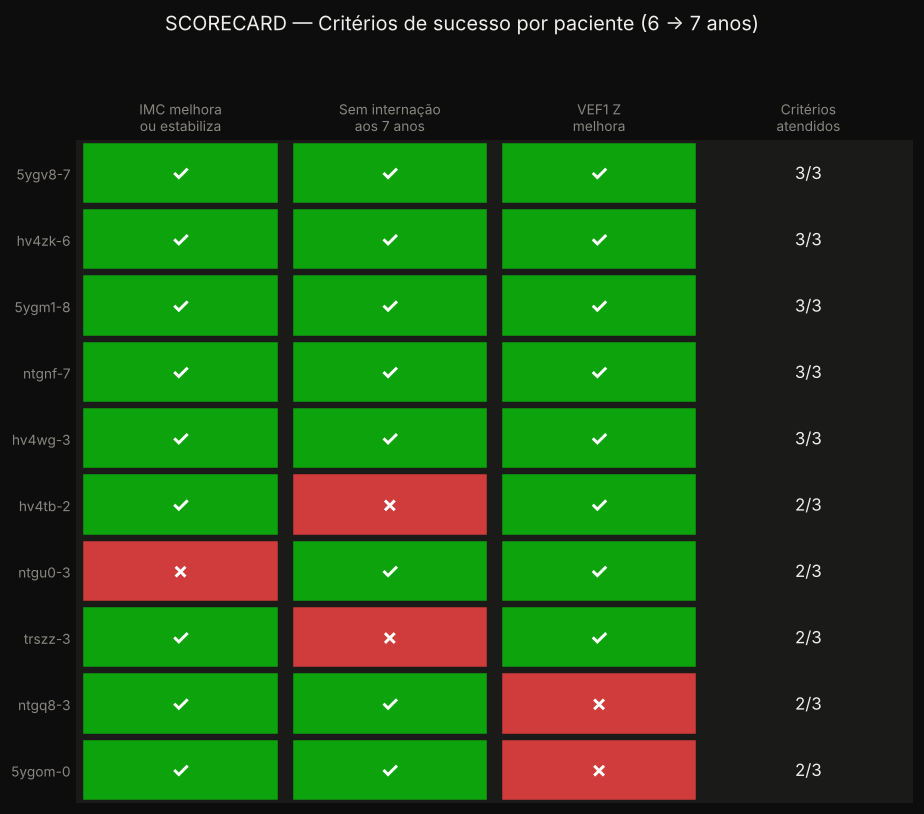

Interpretação:
     3/3 critérios: 5 paciente(s) | 2/3 critérios: 5 paciente(s).
     O scorecard mostra que "o tratamento funcionou" é uma pergunta por paciente: o veredito da coorte esconde quem precisa de revisão.


In [21]:
# -- Scorecard individual -------------------------------------------------------------------------
TRANS = {(1, 0): 'reduziu', (0, 0): 'sem internação', (1, 1): 'persistiu', (0, 1): 'passou a internar'}
ind = pd.DataFrame({
    'idpaciente': COORTE['idpaciente'],
    'Δ IMC': COORTE['imc_t1'] - COORTE['imc_t0'],
    'Δ VEF1 Z': COORTE['VEF1 Z_t1'] - COORTE['VEF1 Z_t0'],
    'Internação': [TRANS[(a, b)] for a, b in zip(i0, i1)],
})
ind['IMC'] = ind['Δ IMC'] >= -TOL_IMC
ind['Int.'] = COORTE['internacao_int_t1'] == 0
ind['VEF1'] = ind['Δ VEF1 Z'] > 0
ind['Critérios'] = ind[['IMC', 'Int.', 'VEF1']].sum(axis=1)
ind = ind.sort_values(['Critérios', 'Δ VEF1 Z'], ascending=[False, False]).reset_index(drop=True)
display(ind[['idpaciente', 'Δ IMC', 'Δ VEF1 Z', 'Internação', 'Critérios']].style.format({'Δ IMC': '{:+.2f}', 'Δ VEF1 Z': '{:+.2f}'}))

fig, ax = plt.subplots(figsize=(8.5, 0.55 * len(ind) + 2))
fig.suptitle(f'SCORECARD — Critérios de sucesso por paciente ({IDADE_BASE} → {IDADE_POS} anos)', fontsize=13)
colunas = [('IMC', 'IMC melhora\nou estabiliza'), ('Int.', 'Sem internação\naos 7 anos'), ('VEF1', 'VEF1 Z\nmelhora')]
for i, row in ind.iterrows():
    for j, (col, _) in enumerate(colunas):
        ok = bool(row[col])
        ax.add_patch(plt.Rectangle((j + 0.04, i + 0.06), 0.92, 0.88, color=C['bom'] if ok else C['critico']))
        ax.text(j + 0.5, i + 0.5, '✓' if ok else '✗', ha='center', va='center', color='#ffffff', fontsize=14, fontweight='bold')
    ax.text(len(colunas) + 0.5, i + 0.5, f"{int(row['Critérios'])}/3", ha='center', va='center', color=C['tinta'], fontsize=11)
ax.set_xlim(0, len(colunas) + 1); ax.set_ylim(len(ind), 0)
ax.set_xticks([j + 0.5 for j in range(len(colunas))] + [len(colunas) + 0.5])
ax.set_xticklabels([r for _, r in colunas] + ['Critérios\natendidos'], fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks([i + 0.5 for i in range(len(ind))]); ax.set_yticklabels(ind['idpaciente'], fontsize=9)
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
mostrar(fig, '09_scorecard')

dist = ind['Critérios'].value_counts().sort_index(ascending=False)
print('Interpretação:')
print('     ' + ' | '.join(f'{k}/3 critérios: {v} paciente(s)' for k, v in dist.items()) + '.')
print('     O scorecard mostra que "o tratamento funcionou" é uma pergunta por paciente: o veredito da coorte esconde quem precisa de revisão.')

In [22]:
# -- Robustez: o resultado depende das escolhas? --------------------------------------------------------
print('=' * 70)
print('  ROBUSTEZ — outras datas de referência e a coorte ampliada')
print('=' * 70)
linhas = []
for mmdd, nome in [('12-31', '31/dez do ano (usado)'), ('06-30', '30/jun do ano'), ('01-01', '1º/jan do ano')]:
    P_ = selecionar_coorte(pares_consecutivos(adicionar_idade(df, mmdd)))
    r = avaliar_coorte(P_)
    linhas.append({'Cenário': f'Idade medida em {nome}', 'Pares': r['n'], 'Δ IMC (mediana)': r['med_d_imc'],
                   'Δ VEF1 Z (mediana)': r['med_d_vef'], '% com VEF1 Z melhor': r['pct_vef_melhora'] * 100,
                   'Internação %': f"{r['taxa_t0'] * 100:.0f} → {r['taxa_t1'] * 100:.0f}", 'Critérios atendidos': f"{r['criterios']}/3"})
R_amp = avaliar_coorte(PARES)
linhas.append({'Cenário': 'Coorte ampliada: todos os pares de anos consecutivos, qualquer idade', 'Pares': R_amp['n'],
               'Δ IMC (mediana)': R_amp['med_d_imc'], 'Δ VEF1 Z (mediana)': R_amp['med_d_vef'],
               '% com VEF1 Z melhor': R_amp['pct_vef_melhora'] * 100,
               'Internação %': f"{R_amp['taxa_t0'] * 100:.0f} → {R_amp['taxa_t1'] * 100:.0f}", 'Critérios atendidos': f"{R_amp['criterios']}/3"})
rob = pd.DataFrame(linhas).set_index('Cenário')
display(rob.style.format({'Δ IMC (mediana)': '{:+.2f}', 'Δ VEF1 Z (mediana)': '{:+.2f}', '% com VEF1 Z melhor': '{:.0f}'}))

print(f"Coorte ampliada ({R_amp['n']} pares, {R_amp['pacientes']} pacientes): Δ IMC mediana {R_amp['med_d_imc']:+.2f} (Wilcoxon p = {R_amp['p_imc']:.3f}); "
      f"Δ VEF1 Z mediana {R_amp['med_d_vef']:+.2f} (p = {R_amp['p_vef']:.2f}); "
      f"internação {R_amp['taxa_t0'] * 100:.0f}% → {R_amp['taxa_t1'] * 100:.0f}% "
      f"({R_amp['reduziu']} deixaram de internar vs {R_amp['passou_a_internar']} passaram a internar; McNemar p = {R_amp['p_int']:.2f}).")
print(f"Regressão à média (corr. VEF1 Z inicial × variação): {br(R['corr_rm'])} na coorte principal e {br(R_amp['corr_rm'])} na ampliada.")
print('Interpretação:')
print('     O número de critérios atendidos muda conforme a data de referência e a seleção dos pacientes, sinal de que 10 pares não bastam para uma conclusão firme.')
print('     A coorte ampliada usa mais dados do mesmo registro e é a leitura mais estável; é o argumento prático para manter e expandir o registro.')

  ROBUSTEZ — outras datas de referência e a coorte ampliada


,Pares,Δ IMC (mediana),Δ VEF1 Z (mediana),% com VEF1 Z melhor,Internação %,Critérios atendidos
Cenário,,,,,,
Idade medida em 31/dez do ano (usado),10,+0.30,+0.30,80,20 → 20,2/3
Idade medida em 30/jun do ano,10,+1.08,+0.15,60,20 → 10,3/3
Idade medida em 1º/jan do ano,7,+1.17,-0.01,43,29 → 0,2/3
"Coorte ampliada: todos os pares de anos consecutivos, qualquer idade",42,+0.64,+0.05,55,29 → 12,3/3


Coorte ampliada (42 pares, 39 pacientes): Δ IMC mediana +0.64 (Wilcoxon p = 0.000); Δ VEF1 Z mediana +0.05 (p = 0.26); internação 29% → 12% (10 deixaram de internar vs 3 passaram a internar; McNemar p = 0.09).
Regressão à média (corr. VEF1 Z inicial × variação): -0,87 na coorte principal e -0,40 na ampliada.
Interpretação:
     O número de critérios atendidos muda conforme a data de referência e a seleção dos pacientes, sinal de que 10 pares não bastam para uma conclusão firme.
     A coorte ampliada usa mais dados do mesmo registro e é a leitura mais estável; é o argumento prático para manter e expandir o registro.


---
## 7. Da Análise à Decisão: Lista de Triagem

In [23]:
# -- Pacientes que merecem revisão no último registro ---------------------------------------------------
d = df.sort_values(['idpaciente', 'ano_seguimento']).copy()
d['vef1_ant'] = d.groupby('idpaciente')['VEF1 Z'].shift(1)
d['imc_ant'] = d.groupby('idpaciente')['imc'].shift(1)
ult = d.groupby('idpaciente').tail(1).set_index('idpaciente')
alertas = pd.DataFrame({
    'Ano': ult['ano_seguimento'], 'Idade': ult['idade'].round(1), 'VEF1 Z': ult['VEF1 Z'],
    'VEF1 abaixo do limite (Z < −1,64)': ult['VEF1 Z'] < LIN_Z,
    'Internação no último registro': ult['internacao'],
    'Queda de VEF1 Z ≥ 0,5': (ult['VEF1 Z'] - ult['vef1_ant']) <= -0.5,
    'Queda de IMC além da tolerância': (ult['imc'] - ult['imc_ant']) < -TOL_IMC,
})
flags = alertas.columns[3:]
alertas['Nº de alertas'] = alertas[flags].astype(int).sum(axis=1)
fila = alertas[alertas['Nº de alertas'] > 0].sort_values(['Nº de alertas', 'VEF1 Z'], ascending=[False, True])
print(f'{len(fila)} de {len(alertas)} pacientes com ao menos um alerta no registro mais recente:')
display(fila.style.format({'VEF1 Z': '{:.2f}'}))
print('Triagem para priorizar revisão clínica a partir de regras simples e transparentes sobre o registro; '
      'não é diagnóstico nem substitui a avaliação do profissional de saúde.')

15 de 41 pacientes com ao menos um alerta no registro mais recente:


,Ano,Idade,VEF1 Z,"VEF1 abaixo do limite (Z < −1,64)",Internação no último registro,"Queda de VEF1 Z ≥ 0,5",Queda de IMC além da tolerância,Nº de alertas
idpaciente,,,,,,,,
trrrn-8,2025,9.600000,-2.32,True,False,True,False,2
ntfkx-7,2025,10.100000,-0.79,False,True,True,False,2
hv3a5-5,2025,10.500000,-2.79,True,False,False,False,1
ntfsu-2,2025,9.000000,-2.10,True,False,False,False,1
ntfkt-6,2025,10.300000,-1.84,True,False,False,False,1
bwrry-0,2025,9.100000,-1.74,True,False,False,False,1
trrul-3,2025,9.000000,-0.52,False,False,True,False,1
hv4tb-2,2025,7.500000,0.03,False,True,False,False,1
trszz-3,2025,7.400000,0.11,False,True,False,False,1


Triagem para priorizar revisão clínica a partir de regras simples e transparentes sobre o registro; não é diagnóstico nem substitui a avaliação do profissional de saúde.


---
## 8. Conclusões

### 8.1 Principais achados

| Achado | Evidência |
|---|---|
| Base longitudinal pequena: **83 registros de 41 pacientes** (idade 6,0–10,8 anos); 36 pacientes têm 2 registros, 3 têm 3 e 2 têm 1 | Seção 1 |
| **Internação em 19,3%** dos registros (16 de 83); sem diferença significativa de IMC, idade ou função pulmonar entre registros com e sem internação | Mann-Whitney, todos p ≥ 0,05 |
| **Modelo transversal** (IMC, idade, internação → VEF1 Z) **não generaliza** | R² = −0,16, MAE 1,04 Z (a média sozinha dá MAE 0,96) |
| **Modelo longitudinal** (registro do ano atual → VEF1 Z do ano seguinte) **funciona** | R² = 0,72, MAE 0,50 Z, RMSE 0,63 Z, com 42 pares de 39 pacientes |
| Quase todo o poder do modelo longitudinal vem do **próprio VEF1 Z anterior**; repetir o último valor rende o mesmo (R² 0,77) | Seção 4 |
| **Internação não é previsível** com função pulmonar, IMC e idade | Precisão 0,26 · recall 0,56 · F1 0,36 · AUC 0,55; todos os IC 95% das razões de chance incluem 1 |
| Aos 6 → 7 anos (n = 10), **2 de 3 critérios** atendidos: IMC estável/melhor e VEF1 Z melhor; internação não diminuiu (20% → 20%) | Seção 6 |
| O veredito **muda com a data de referência** (2/3, 3/3, 2/3) e a coorte ampliada (42 pares) mostra 3/3 | Análise de robustez |

### 8.2 O tratamento funcionou?

**Com os dados atuais, não é possível afirmar.** Os resultados apontam na direção favorável, mas nenhum é estatisticamente sólido:

1. **IMC:** mediana de +0,30 kg/m², critério atendido. O IMC sobe naturalmente com o crescimento e a base não traz o IMC ajustado para idade (percentil ou escore Z), então parte do ganho é esperada.
2. **Internação:** 2 de 10 pacientes nos dois momentos; 1 deixou de internar e 1 passou a internar (McNemar p = 1,00). Na coorte ampliada, a taxa cai de 29% para 12% (McNemar p = 0,09), tendência sem significância.
3. **VEF1 Z:** mediana de +0,30 Z, com 8 de 10 pacientes melhorando (Wilcoxon p = 0,39). A correlação de −0,87 entre o valor inicial e a variação é a assinatura de **regressão à média**: quem começa baixo tende a subir, quem começa alto tende a cair.

Além disso, **a base não identifica quem recebeu qual tratamento nem tem grupo controle**. O que se mede é a evolução da coorte, não o efeito causal de uma intervenção.

### 8.3 O que o registro de pacientes permite decidir

- **Priorizar acompanhamento:** o VEF1 Z de hoje prevê o do próximo ano com erro típico de 0,5 Z; pacientes com VEF1 baixo tendem a permanecer baixos. A lista de triagem (seção 7) aponta 15 dos 41 pacientes com algum alerta no último registro.
- **Medir a evolução da coorte** com critérios explícitos e repetíveis (IMC, internação, função pulmonar), que podem ser recalculados a cada novo ano de seguimento.
- **Saber o que ainda falta coletar:** internação não é prevista pelas variáveis atuais. Registrar exacerbações, microbiologia, adesão ao tratamento, **o tratamento em si** e fatores sociais é o que transformaria o registro em ferramenta de decisão causal.
- **Reconhecer incerteza:** com 10 pares, uma troca de paciente muda o veredito. Mais pacientes e mais anos de seguimento são o ganho de maior valor.

### 8.4 Limitações

1. **Amostra pequena:** 41 pacientes, 10 na comparação 6 → 7 anos; poder estatístico baixo e testes sensíveis a um único paciente.
2. **Sem variável de tratamento e sem grupo controle:** impossível separar efeito do tratamento de crescimento, regressão à média e acompanhamento habitual.
3. **Data do seguimento aproximada:** a base traz só o ano; a idade foi calculada para 31/dez, e o resultado muda com outra data (ver robustez).
4. **IMC bruto:** sem ajuste para idade e sexo; o sexo não consta na base.
5. **Internação binária e por ano:** sem número, duração ou causa das internações.
6. **Um registro com CVF Z = 6,13** (185% do predito), provável erro de medição; mantido e sinalizado.
7. **Validação:** cruzada por paciente, sem amostra externa; as métricas são estimativas otimistas para dados novos.

### 8.5 Considerações finais

O notebook mostra o valor de um registro de pacientes em duas frentes. Onde há **série temporal** (VEF1 de um ano para outro), o registro sustenta previsões úteis e uma avaliação transparente de desfechos. Onde faltam **variáveis** (internação, tratamento), ele mostra honestamente o limite do que os dados atuais respondem e indica o que passar a coletar. O resultado mais importante é metodológico: critérios de sucesso definidos antes, métricas fora da amostra e análise de robustez impedem que um número isolado seja lido como prova.

---
*Dados: registro de pacientes pseudonimizado (`dados_fin.csv`), 83 registros de 41 pacientes, 2022–2025.*